In [90]:
# CELL 1: Import libraries and load hourly energy data

import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

# File paths
DATA_PATH = "../dataset/feature_engineered_hourly.csv"

OUTPUT_DIR = "../evaluation/advanced_forecasting"
PLOT_DIR = "../visualizations/advanced_forecasting"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

# Load dataset
df = pd.read_csv(DATA_PATH)

# Identify timestamp column
timestamp_candidates = [
    "Timestamp", "Datetime", "DateTime",
    "Date", "datetime", "timestamp"
]

timestamp_col = next(
    (col for col in timestamp_candidates if col in df.columns),
    None
)

# Handle CSV files where the index was saved as the first column
if timestamp_col is None:
    timestamp_col = df.columns[0]

df[timestamp_col] = pd.to_datetime(
    df[timestamp_col], errors="coerce"
)

df = df.dropna(subset=[timestamp_col])
df = df.set_index(timestamp_col).sort_index()

if "Energy_kWh" not in df.columns:
    raise ValueError("Energy_kWh column not found.")

df["Energy_kWh"] = pd.to_numeric(
    df["Energy_kWh"], errors="coerce"
)

df = df.dropna(subset=["Energy_kWh"])

# Data validation
if df.index.has_duplicates:
    raise ValueError("Duplicate timestamps found. Resolve them before forecasting.")

if not np.isfinite(df["Energy_kWh"]).all():
    raise ValueError("Non-finite energy values found.")

if (df["Energy_kWh"] < 0).any():
    raise ValueError("Negative energy values found. Check the dataset.")

if not (df.index.minute == 0).all() or not (df.index.second == 0).all():
    raise ValueError("Dataset timestamps are not aligned to full hours.")

print("Dataset loaded and validated successfully!")
print("Shape:", df.shape)
print("Date range:", df.index.min(), "to", df.index.max())
print("Missing energy values:", df["Energy_kWh"].isna().sum())
print("Duplicate timestamps:", df.index.has_duplicates)

display(df[["Energy_kWh"]].head())


Dataset loaded and validated successfully!
Shape: (31428, 15)
Date range: 2007-01-01 00:00:00 to 2010-11-26 20:00:00
Missing energy values: 0
Duplicate timestamps: False


,Energy_kWh
DateTime,
2007-01-01 00:00:00,2.550633
2007-01-01 01:00:00,2.523400
2007-01-01 02:00:00,2.582333
2007-01-01 03:00:00,2.541667
2007-01-01 04:00:00,2.475733


Daily time series prepared successfully!
Complete consecutive days: 443
Start date: 2007-08-09 00:00:00
End date: 2008-10-24 00:00:00
Average daily consumption: 25.782 kWh
Minimum daily consumption: 4.172 kWh
Maximum daily consumption: 54.983 kWh


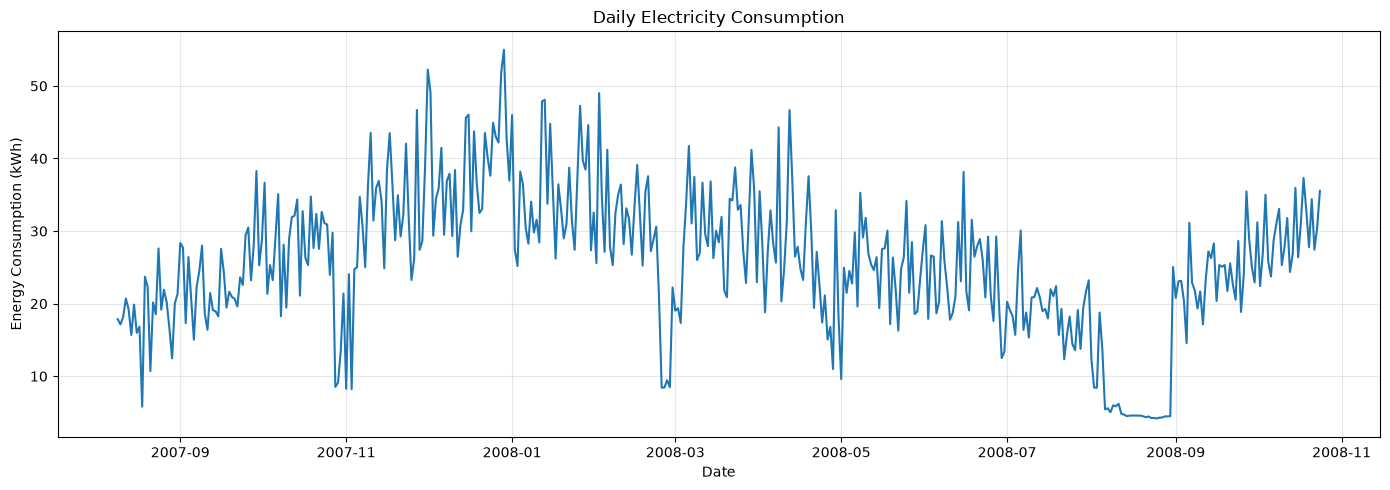

In [91]:
# CELL 2: Daily energy aggregation and continuous time-series preparation

hourly_energy = df["Energy_kWh"].sort_index()

# Count actual hourly records per calendar day
daily_count = hourly_energy.resample("D").count()

# Sum hourly energy to calculate daily energy consumption
daily_sum = hourly_energy.resample("D").sum(min_count=24)

# Retain only days with exactly 24 hourly records
daily_energy = daily_sum[daily_count == 24].dropna()

if len(daily_energy) == 0:
    raise ValueError("No complete 24-hour days found.")

# Find the longest continuous sequence of complete days
valid_dates = daily_energy.index

groups = (
    valid_dates.to_series()
    .diff()
    .ne(pd.Timedelta(days=1))
    .cumsum()
)

longest_group = groups.value_counts().idxmax()

daily_energy = daily_energy.loc[groups == longest_group].asfreq("D")

if daily_energy.isna().any():
    raise ValueError("Missing values found in the selected daily time series.")

print("Daily time series prepared successfully!")
print("Complete consecutive days:", len(daily_energy))
print("Start date:", daily_energy.index.min())
print("End date:", daily_energy.index.max())
print("Average daily consumption:", round(daily_energy.mean(), 3), "kWh")
print("Minimum daily consumption:", round(daily_energy.min(), 3), "kWh")
print("Maximum daily consumption:", round(daily_energy.max(), 3), "kWh")

plt.figure(figsize=(14, 5))
plt.plot(daily_energy.index, daily_energy.values)
plt.title("Daily Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (kWh)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "daily_energy_timeseries.png"),
    dpi=300
)
plt.show()


Training observations: 354
Testing observations: 89

Training period: 2007-08-09 00:00:00 to 2008-07-27 00:00:00
Testing period: 2008-07-28 00:00:00 to 2008-10-24 00:00:00


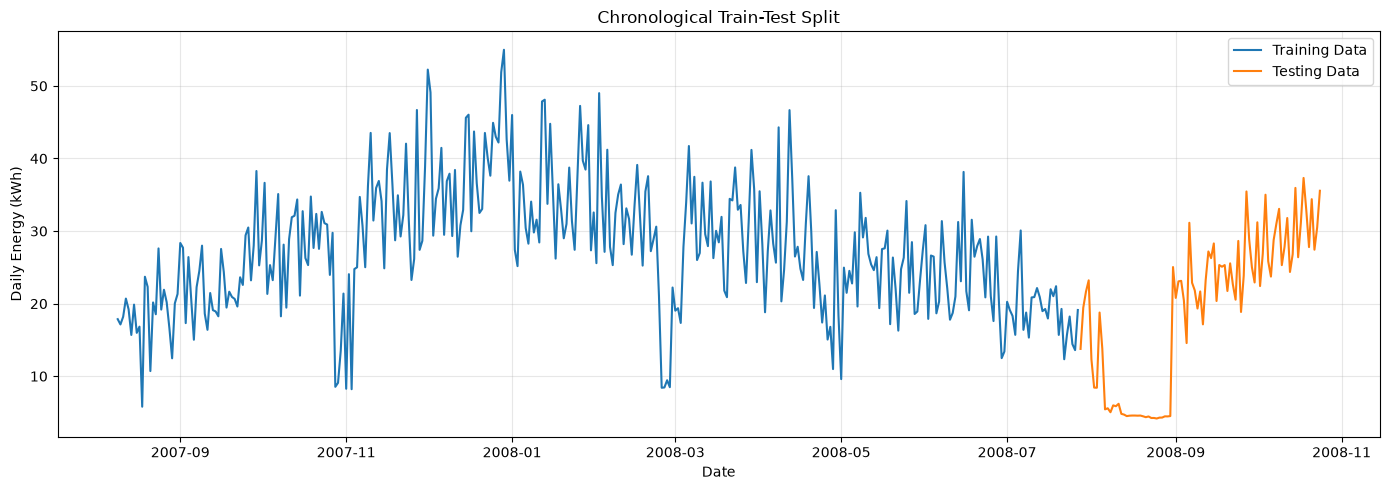

In [92]:
# CELL 3: Chronological train-test split

split_index = int(len(daily_energy) * 0.80)

train = daily_energy.iloc[:split_index]
test = daily_energy.iloc[split_index:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("\nTraining period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

assert train.index.max() < test.index.min()
assert len(train) > 100
assert len(test) > 0

plt.figure(figsize=(14, 5))
plt.plot(train.index, train, label="Training Data")
plt.plot(test.index, test, label="Testing Data")
plt.title("Chronological Train-Test Split")
plt.xlabel("Date")
plt.ylabel("Daily Energy (kWh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "train_test_split.png"), dpi=300)
plt.show()


In [93]:
# CELL 4: Train ARIMA model

arima_model = ARIMA(
    train,
    order=(2, 1, 2)
)

arima_fitted = arima_model.fit()

arima_forecast = arima_fitted.forecast(steps=len(test))

arima_forecast = pd.Series(
    np.asarray(arima_forecast),
    index=test.index,
    name="ARIMA"
)

print(arima_fitted.summary())
print("\nARIMA forecasting completed!")
display(arima_forecast.head())


                               SARIMAX Results                                
Dep. Variable:             Energy_kWh   No. Observations:                  354
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -1174.487
Date:                Tue, 24 Nov 2026   AIC                           2358.974
Time:                        21:08:23   BIC                           2378.306
Sample:                    08-09-2007   HQIC                          2366.667
                         - 07-27-2008                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6113      0.443     -1.378      0.168      -1.481       0.258
ar.L2          0.1151      0.135      0.855      0.393      -0.149       0.379
ma.L1         -0.0343      0.441     -0.078      0.9

DateTime
2008-07-28    17.749128
2008-07-29    17.192979
2008-07-30    17.374827
2008-07-31    17.199668
2008-08-01    17.327667
Freq: D, Name: ARIMA, dtype: float64

In [94]:
# CELL 5: Train SARIMA model

sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fitted = sarima_model.fit(disp=False, maxiter=200)

sarima_forecast = sarima_fitted.forecast(steps=len(test))

sarima_forecast = pd.Series(
    np.asarray(sarima_forecast),
    index=test.index,
    name="SARIMA"
)

print(sarima_fitted.summary())
print("\nSARIMA forecasting completed!")
display(sarima_forecast.head())


                                     SARIMAX Results                                     
Dep. Variable:                        Energy_kWh   No. Observations:                  354
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood               -1095.139
Date:                           Tue, 24 Nov 2026   AIC                           2200.277
Time:                                   21:08:23   BIC                           2219.378
Sample:                               08-09-2007   HQIC                          2207.890
                                    - 07-27-2008                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1142      0.083      1.375      0.169      -0.049       0.277
ma.L1         -0.7182      0.059    -12.102

DateTime
2008-07-28    12.142054
2008-07-29    17.864422
2008-07-30    13.394866
2008-07-31    12.046380
2008-08-01    16.709675
Freq: D, Name: SARIMA, dtype: float64

In [95]:
# CELL 6: Train Prophet model

prophet_train = pd.DataFrame({
    "ds": train.index,
    "y": train.values
})

prophet_model = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive"
)

prophet_model.fit(prophet_train)

future = prophet_model.make_future_dataframe(
    periods=len(test),
    freq="D"
)

prophet_output = prophet_model.predict(future)

prophet_forecast = pd.Series(
    prophet_output.tail(len(test))["yhat"].to_numpy(),
    index=test.index,
    name="Prophet"
)

print("Prophet forecasting completed!")
display(prophet_forecast.head())


21:08:23 - cmdstanpy - INFO - Chain [1] start processing
21:08:23 - cmdstanpy - INFO - Chain [1] done processing


Prophet forecasting completed!


DateTime
2008-07-28    15.568148
2008-07-29    21.339142
2008-07-30    16.810232
2008-07-31    15.426305
2008-08-01    19.930460
Freq: D, Name: Prophet, dtype: float64

In [96]:

# CELL 7: Evaluate and compare forecasting models

# 1. Combine actual and predicted values
forecast_results = pd.DataFrame({
    "Actual": test,
    "ARIMA": arima_forecast,
    "SARIMA": sarima_forecast,
    "Prophet": prophet_forecast
})

# 2. Validate predictions
if forecast_results.isna().any().any():
    raise ValueError("Missing values found in actual or predicted results.")

if not np.isfinite(forecast_results.to_numpy()).all():
    raise ValueError("Non-finite values found in forecasting results.")

# 3. Define evaluation metrics
def calculate_metrics(actual, predicted):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    if len(actual) != len(predicted):
        raise ValueError("Actual and predicted lengths do not match.")

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    # Safe MAPE calculation
    nonzero_mask = actual != 0

    if nonzero_mask.any():
        mape = np.mean(
            np.abs(
                (actual[nonzero_mask] - predicted[nonzero_mask])
                / actual[nonzero_mask]
            )
        ) * 100
    else:
        mape = np.nan

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "MAPE (%)": mape
    }

# 4. Evaluate all models on the same test period
metrics = pd.DataFrame({
    "ARIMA": calculate_metrics(test, arima_forecast),
    "SARIMA": calculate_metrics(test, sarima_forecast),
    "Prophet": calculate_metrics(test, prophet_forecast)
}).T

# 5. Sort models by RMSE
metrics = metrics.sort_values(by="RMSE", ascending=True)

print("=" * 60)
print("STATISTICAL FORECASTING MODEL PERFORMANCE")
print("=" * 60)

display(metrics.round(4))

# 6. Identify best model based on RMSE
best_model = metrics["RMSE"].idxmin()

print("\nBest model based on RMSE:", best_model)
print("Best RMSE:", round(metrics.loc[best_model, "RMSE"], 4))
print("Best MAE:", round(metrics.loc[best_model, "MAE"], 4))
print("Best R2:", round(metrics.loc[best_model, "R2"], 4))

# 7. Save evaluation results
metrics.to_csv(
    os.path.join(OUTPUT_DIR, "statistical_model_comparison.csv"),
    index=True
)

forecast_results.to_csv(
    os.path.join(OUTPUT_DIR, "statistical_forecast_predictions.csv"),
    index=True
)

print("\nEvaluation results saved successfully!")
print("Output folder:", OUTPUT_DIR)


STATISTICAL FORECASTING MODEL PERFORMANCE


,MAE,MSE,RMSE,R2,MAPE (%)
ARIMA,9.6891,113.9687,10.6756,-0.0340,99.4544
SARIMA,10.5337,132.2065,11.4981,-0.1994,94.5951
Prophet,11.7434,165.6059,12.8688,-0.5025,109.2022



Best model based on RMSE: ARIMA
Best RMSE: 10.6756
Best MAE: 9.6891
Best R2: -0.034

Evaluation results saved successfully!
Output folder: ../evaluation/advanced_forecasting


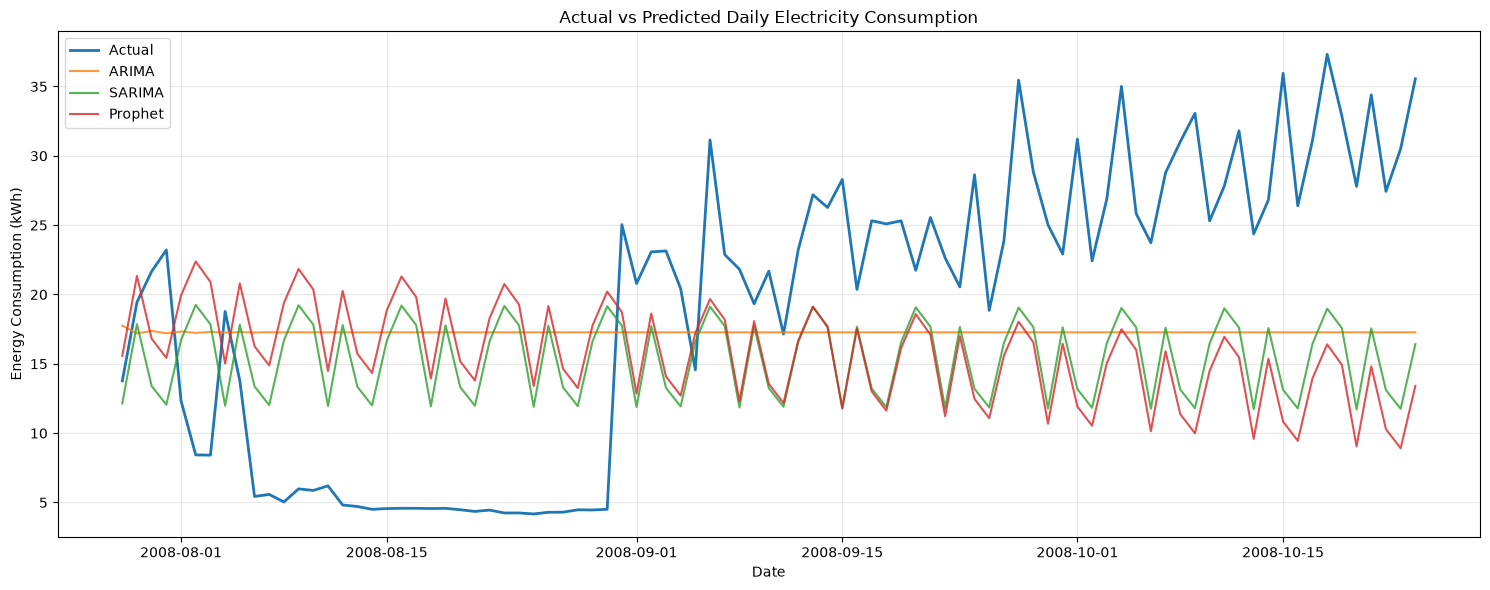

In [97]:
# CELL 8: Plot actual vs predicted consumption

plt.figure(figsize=(15, 6))

plt.plot(test.index, test.values, label="Actual", linewidth=2)
plt.plot(test.index, arima_forecast.values, label="ARIMA", alpha=0.8)
plt.plot(test.index, sarima_forecast.values, label="SARIMA", alpha=0.8)
plt.plot(test.index, prophet_forecast.values, label="Prophet", alpha=0.8)

plt.title("Actual vs Predicted Daily Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (kWh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "statistical_forecast_comparison.png"),
    dpi=300
)

plt.show()


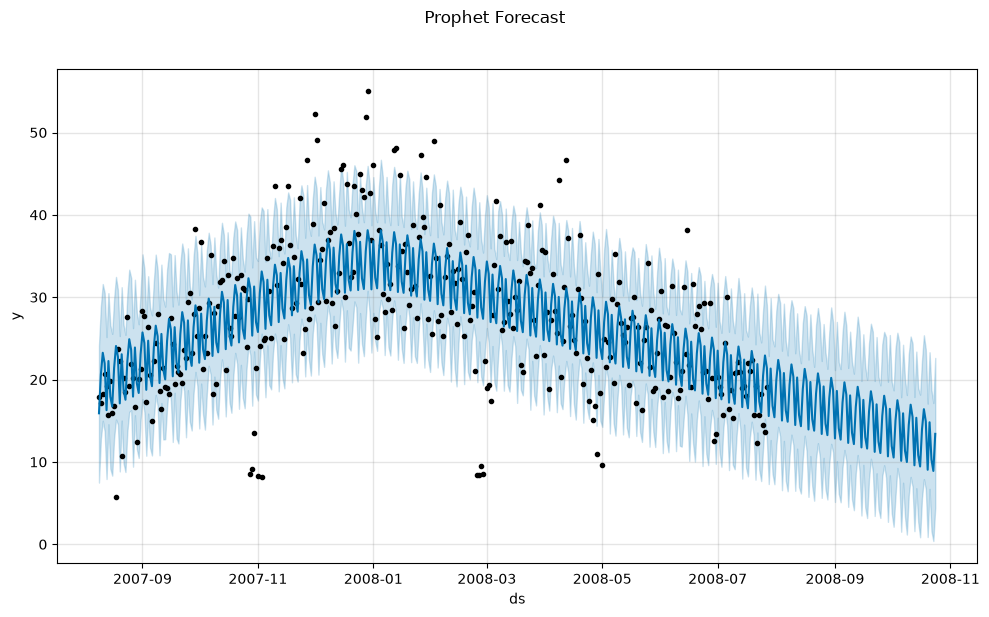

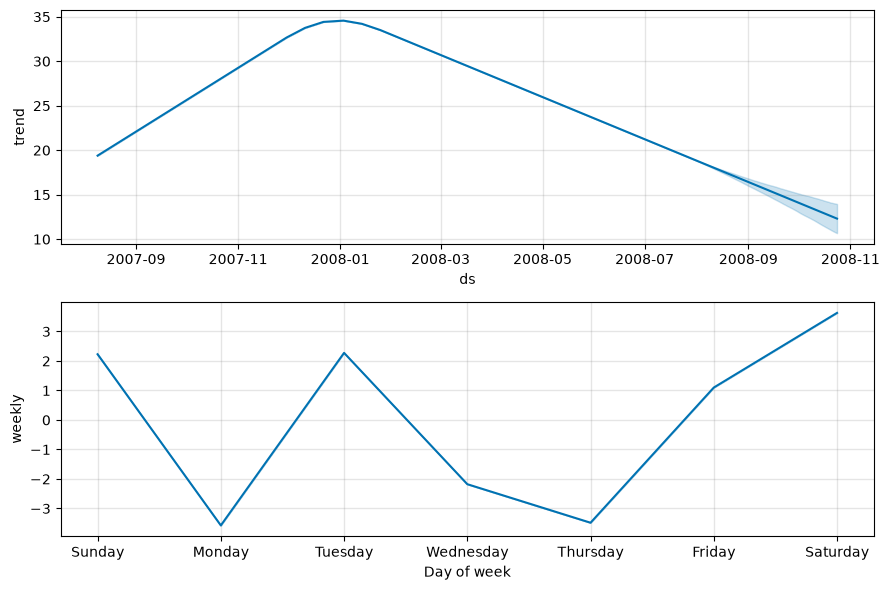

In [98]:
# CELL 9: Prophet trend and seasonality components

fig1 = prophet_model.plot(prophet_output)
fig1.suptitle("Prophet Forecast", y=1.02)
fig1.tight_layout()
fig1.savefig(
    os.path.join(PLOT_DIR, "prophet_forecast.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

fig2 = prophet_model.plot_components(prophet_output)
fig2.tight_layout()
fig2.savefig(
    os.path.join(PLOT_DIR, "prophet_components.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [99]:
# CELL 10: Save Initial Statistical Forecasting Summary

import pandas as pd
import os

summary = pd.DataFrame({
    "Item": [
        "Forecasting methods",
        "Aggregation frequency",
        "Training observations",
        "Testing observations",
        "Best initial model before tuning",
        "Initial best model RMSE",
        "Initial best model MAE"
    ],
    "Result": [
        "ARIMA, SARIMA, Prophet",
        "Daily energy consumption (kWh)",
        len(train),
        len(test),
        best_model,
        round(metrics.loc[best_model, "RMSE"], 4),
        round(metrics.loc[best_model, "MAE"], 4)
    ]
})

summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "task1_forecasting_summary.csv"
    ),
    index=False
)

print("INITIAL STATISTICAL FORECASTING SUMMARY")
display(summary)

print("\nNote: This summary is before SARIMA hyperparameter tuning.")
print("The final tuned-model comparison is reported in Cell 18.")

print("\nSummary saved successfully!")

INITIAL STATISTICAL FORECASTING SUMMARY


,Item,Result
0,Forecasting methods,"ARIMA, SARIMA, Prophet"
1,Aggregation frequency,Daily energy consumption (kWh)
2,Training observations,354
3,Testing observations,89
4,Best initial model before tuning,ARIMA
5,Initial best model RMSE,10.6756
6,Initial best model MAE,9.6891



Note: This summary is before SARIMA hyperparameter tuning.
The final tuned-model comparison is reported in Cell 18.

Summary saved successfully!


DAILY DATA COVERAGE REPORT
Total calendar days: 1426
Complete days: 1298
Incomplete days: 128

Hourly records per day:


,Number_of_Days
Total_Hourly_Records,
0,101
2,1
4,5
5,3
6,1
8,1
9,1
10,4
12,2



First 15 incomplete days:


,Total_Hourly_Records,Is_Complete
DateTime,,
2007-04-28,0,False
2007-04-29,0,False
2007-04-30,0,False
2007-05-01,0,False
2007-05-02,0,False
2007-05-03,0,False
2007-05-04,0,False
2007-05-05,0,False
2007-05-06,0,False


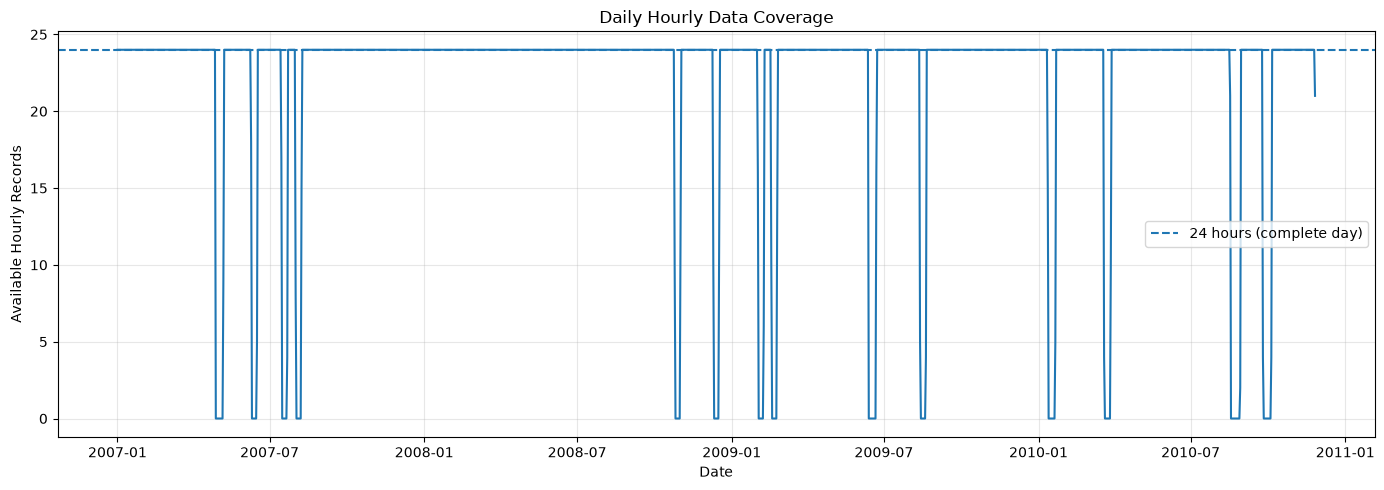

In [100]:
# CELL 11: Diagnose daily data coverage

daily_coverage = df["Energy_kWh"].resample("D").agg(
    Total_Hourly_Records="count"
)

daily_coverage["Is_Complete"] = (
    daily_coverage["Total_Hourly_Records"] == 24
)

print("DAILY DATA COVERAGE REPORT")
print("=" * 50)

print("Total calendar days:", len(daily_coverage))
print("Complete days:", daily_coverage["Is_Complete"].sum())
print("Incomplete days:", (~daily_coverage["Is_Complete"]).sum())

print("\nHourly records per day:")
display(
    daily_coverage["Total_Hourly_Records"]
    .value_counts()
    .sort_index()
    .to_frame("Number_of_Days")
)

print("\nFirst 15 incomplete days:")
display(
    daily_coverage[
        ~daily_coverage["Is_Complete"]
    ].head(15)
)

# Visualize daily coverage
plt.figure(figsize=(14, 5))

plt.plot(
    daily_coverage.index,
    daily_coverage["Total_Hourly_Records"]
)

plt.axhline(
    y=24,
    linestyle="--",
    label="24 hours (complete day)"
)

plt.title("Daily Hourly Data Coverage")
plt.xlabel("Date")
plt.ylabel("Available Hourly Records")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "daily_data_coverage.png"),
    dpi=300
)

plt.show()


In [101]:
# CELL 12: Analyze complete and incomplete daily periods

complete_mask = daily_coverage["Is_Complete"]

# Identify continuous groups of complete days
complete_dates = daily_coverage.index[complete_mask]

if len(complete_dates) == 0:
    raise ValueError("No complete days available.")

date_groups = (
    complete_dates.to_series()
    .diff()
    .ne(pd.Timedelta(days=1))
    .cumsum()
)

period_summary = (
    pd.DataFrame({"Date": complete_dates, "Group": date_groups.values})
    .groupby("Group")
    .agg(
        Start_Date=("Date", "min"),
        End_Date=("Date", "max"),
        Complete_Days=("Date", "count")
    )
    .sort_values("Complete_Days", ascending=False)
)

period_summary["Duration_Days"] = (
    period_summary["End_Date"] - period_summary["Start_Date"]
).dt.days + 1

print("CONTINUOUS COMPLETE-DAY PERIODS")
display(period_summary.head(10))

print("\nLongest continuous period:")
display(period_summary.head(1))


CONTINUOUS COMPLETE-DAY PERIODS


,Start_Date,End_Date,Complete_Days,Duration_Days
Group,,,,
5,2007-08-09,2008-10-24,443,443
11,2009-08-21,2010-01-11,144,144
13,2010-03-29,2010-08-16,141,141
1,2007-01-01,2007-04-27,117,117
9,2009-02-25,2009-06-12,108,108
12,2010-01-22,2010-03-19,57,57
15,2010-10-06,2010-11-25,51,51
10,2009-06-23,2009-08-12,51,51
7,2008-12-18,2009-01-31,45,45



Longest continuous period:


,Start_Date,End_Date,Complete_Days,Duration_Days
Group,,,,
5,2007-08-09,2008-10-24,443,443


In [102]:
# CELL 13: Seasonal Naive Baseline (7-day seasonality)

# Use the last 7 training days as the repeating weekly pattern
last_week = train.iloc[-7:].to_numpy()

# Generate forecasts for the complete test period
seasonal_naive_forecast = pd.Series(
    np.resize(last_week, len(test)),
    index=test.index,
    name="Seasonal_Naive"
)

# Evaluate baseline
baseline_metrics = calculate_metrics(
    test,
    seasonal_naive_forecast
)

print("SEASONAL NAIVE BASELINE PERFORMANCE")
display(
    pd.DataFrame(
        [baseline_metrics],
        index=["Seasonal Naive"]
    ).round(4)
)

# Compare baseline with existing models
all_metrics = metrics.copy()

all_metrics.loc["Seasonal Naive"] = baseline_metrics

all_metrics = all_metrics.sort_values("RMSE")

print("\nCOMPLETE MODEL COMPARISON")
display(all_metrics.round(4))

# Save comparison
all_metrics.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "statistical_models_with_baseline.csv"
    )
)


SEASONAL NAIVE BASELINE PERFORMANCE


,MAE,MSE,RMSE,R2,MAPE (%)
Seasonal Naive,9.9809,126.7805,11.2597,-0.1502,93.7508



COMPLETE MODEL COMPARISON


,MAE,MSE,RMSE,R2,MAPE (%)
ARIMA,9.6891,113.9687,10.6756,-0.0340,99.4544
Seasonal Naive,9.9809,126.7805,11.2597,-0.1502,93.7508
SARIMA,10.5337,132.2065,11.4981,-0.1994,94.5951
Prophet,11.7434,165.6059,12.8688,-0.5025,109.2022


In [103]:
# CELL 14: SARIMA hyperparameter tuning

import warnings

sarima_candidates = [
    ((1, 1, 0), (1, 0, 0, 7)),
    ((1, 1, 0), (0, 1, 0, 7)),
    ((1, 1, 0), (1, 1, 0, 7)),
    ((0, 1, 1), (1, 0, 0, 7)),
    ((0, 1, 1), (0, 1, 0, 7)),
    ((1, 1, 1), (1, 0, 0, 7))
]

sarima_tuning_results = []

for order, seasonal_order in sarima_candidates:

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            candidate = SARIMAX(
                train,
                order=order,
                seasonal_order=seasonal_order,
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            fitted_candidate = candidate.fit(
                disp=False,
                maxiter=200
            )

        converged = fitted_candidate.mle_retvals.get(
            "converged", False
        )

        sarima_tuning_results.append({
            "Order": order,
            "Seasonal_Order": seasonal_order,
            "AIC": fitted_candidate.aic,
            "BIC": fitted_candidate.bic,
            "Converged": converged,
            "Model": fitted_candidate
        })

        print(
            f"Tested SARIMA{order}x{seasonal_order} "
            f"| AIC: {fitted_candidate.aic:.2f} "
            f"| Converged: {converged}"
        )

    except Exception as error:
        print(
            f"Failed SARIMA{order}x{seasonal_order}: {error}"
        )

if not sarima_tuning_results:
    raise RuntimeError("No SARIMA candidate could be fitted.")

# Prefer converged models; if none converged, show that clearly
converged_results = [
    result for result in sarima_tuning_results
    if result["Converged"]
]

selection_pool = (
    converged_results
    if converged_results
    else sarima_tuning_results
)

best_sarima_result = min(
    selection_pool,
    key=lambda result: result["AIC"]
)

best_sarima_model = best_sarima_result["Model"]

print("\nSelected SARIMA configuration:")
print("Order:", best_sarima_result["Order"])
print("Seasonal order:", best_sarima_result["Seasonal_Order"])
print("AIC:", round(best_sarima_result["AIC"], 3))
print("Converged:", best_sarima_result["Converged"])

# Display tuning results without model objects
tuning_table = pd.DataFrame([
    {
        "Order": str(result["Order"]),
        "Seasonal Order": str(result["Seasonal_Order"]),
        "AIC": result["AIC"],
        "BIC": result["BIC"],
        "Converged": result["Converged"]
    }
    for result in sarima_tuning_results
]).sort_values("AIC")

display(tuning_table.round(3))

tuning_table.to_csv(
    os.path.join(OUTPUT_DIR, "sarima_tuning_results.csv"),
    index=False
)


Tested SARIMA(1, 1, 0)x(1, 0, 0, 7) | AIC: 2348.94 | Converged: True
Tested SARIMA(1, 1, 0)x(0, 1, 0, 7) | AIC: 2501.36 | Converged: True
Tested SARIMA(1, 1, 0)x(1, 1, 0, 7) | AIC: 2346.08 | Converged: True
Tested SARIMA(0, 1, 1)x(1, 0, 0, 7) | AIC: 2309.07 | Converged: True
Tested SARIMA(0, 1, 1)x(0, 1, 0, 7) | AIC: 2468.11 | Converged: True
Tested SARIMA(1, 1, 1)x(1, 0, 0, 7) | AIC: 2298.50 | Converged: True

Selected SARIMA configuration:
Order: (1, 1, 1)
Seasonal order: (1, 0, 0, 7)
AIC: 2298.496
Converged: True


,Order,Seasonal Order,AIC,BIC,Converged
5,"(1, 1, 1)","(1, 0, 0, 7)",2298.496,2313.870,True
3,"(0, 1, 1)","(1, 0, 0, 7)",2309.067,2320.606,True
2,"(1, 1, 0)","(1, 1, 0, 7)",2346.082,2357.551,True
0,"(1, 1, 0)","(1, 0, 0, 7)",2348.940,2360.470,True
4,"(0, 1, 1)","(0, 1, 0, 7)",2468.113,2475.794,True
1,"(1, 1, 0)","(0, 1, 0, 7)",2501.362,2509.049,True


In [104]:
# CELL 15: Forecast and evaluate tuned SARIMA

tuned_sarima_forecast = best_sarima_model.forecast(
    steps=len(test)
)

tuned_sarima_forecast = pd.Series(
    np.asarray(tuned_sarima_forecast),
    index=test.index,
    name="Tuned_SARIMA"
)

tuned_sarima_metrics = calculate_metrics(
    test,
    tuned_sarima_forecast
)

print("TUNED SARIMA PERFORMANCE")
display(
    pd.DataFrame(
        [tuned_sarima_metrics],
        index=["Tuned SARIMA"]
    ).round(4)
)

# Compare with existing models and baseline
updated_metrics = metrics.copy()

updated_metrics.loc["Tuned SARIMA"] = tuned_sarima_metrics
updated_metrics.loc["Seasonal Naive"] = baseline_metrics

updated_metrics = updated_metrics.sort_values("RMSE")

print("\nUPDATED MODEL COMPARISON")
display(updated_metrics.round(4))

updated_metrics.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "updated_statistical_model_comparison.csv"
    )
)

tuned_sarima_forecast.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "tuned_sarima_predictions.csv"
    )
)


TUNED SARIMA PERFORMANCE


,MAE,MSE,RMSE,R2,MAPE (%)
Tuned SARIMA,9.4488,111.1641,10.5434,-0.0085,102.625



UPDATED MODEL COMPARISON


,MAE,MSE,RMSE,R2,MAPE (%)
Tuned SARIMA,9.4488,111.1641,10.5434,-0.0085,102.6250
ARIMA,9.6891,113.9687,10.6756,-0.0340,99.4544
Seasonal Naive,9.9809,126.7805,11.2597,-0.1502,93.7508
SARIMA,10.5337,132.2065,11.4981,-0.1994,94.5951
Prophet,11.7434,165.6059,12.8688,-0.5025,109.2022


RESIDUAL SUMMARY


,Residuals
count,354.000000
mean,0.055025
std,6.721012
min,-21.412640
25%,-4.652668
50%,-0.121397
75%,3.857563
max,18.640474


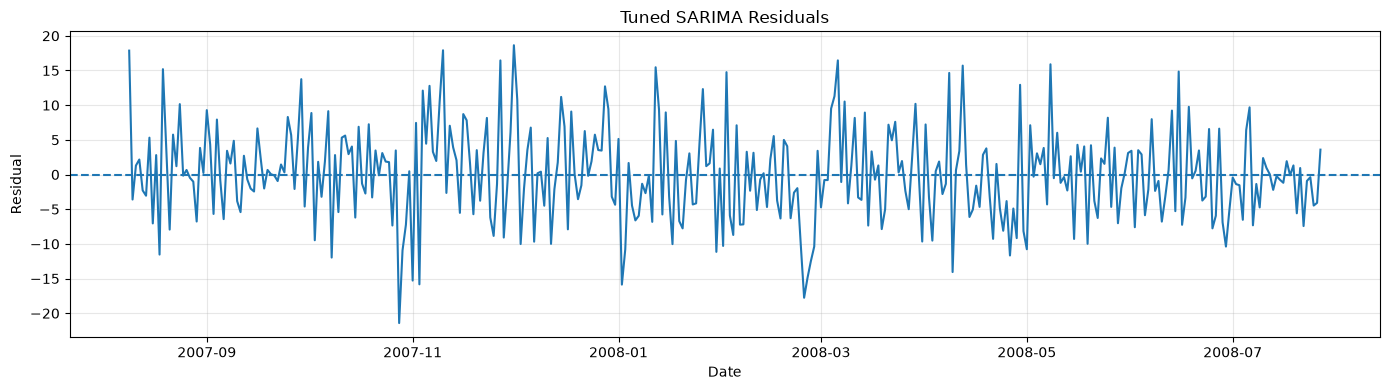

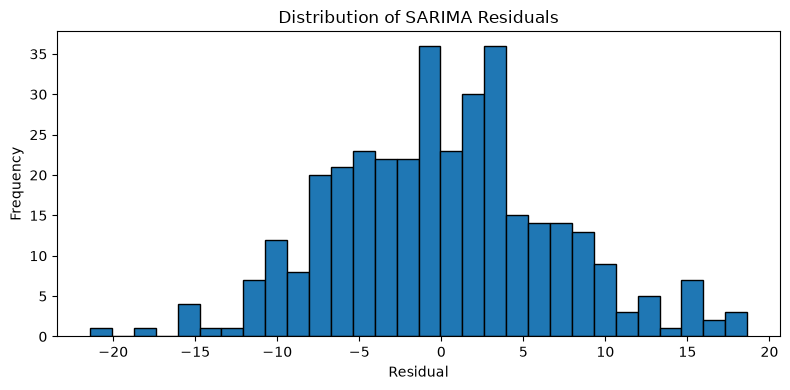

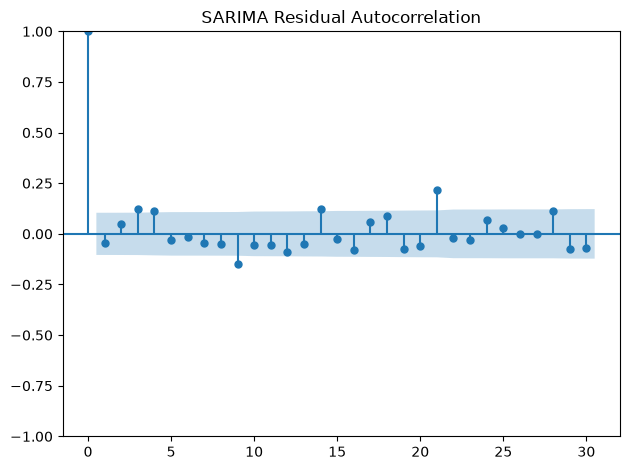

LJUNG-BOX TEST


,lb_stat,lb_pvalue
7,12.522022,0.084647
14,32.922748,0.002956
21,61.022898,0.000009



JARQUE-BERA TEST
Statistic: 1.6522
p-value: 0.437758

Interpretation:
Residual autocorrelation remains at one or more tested lags.
No significant deviation from normality detected.


In [105]:
# CELL 16: Tuned SARIMA residual diagnostics

from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from scipy.stats import jarque_bera

# Extract residuals
residuals = best_sarima_model.resid.dropna()

# Residual summary
print("RESIDUAL SUMMARY")
display(residuals.describe().to_frame("Residuals"))

# Residual time-series plot
plt.figure(figsize=(14, 4))
plt.plot(residuals.index, residuals.values)
plt.axhline(0, linestyle="--")
plt.title("Tuned SARIMA Residuals")
plt.xlabel("Date")
plt.ylabel("Residual")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "sarima_residuals.png"),
    dpi=300
)
plt.show()

# Residual distribution
plt.figure(figsize=(8, 4))
plt.hist(residuals, bins=30, edgecolor="black")
plt.title("Distribution of SARIMA Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "sarima_residual_distribution.png"),
    dpi=300
)
plt.show()

# Residual autocorrelation
plot_acf(residuals, lags=30)
plt.title("SARIMA Residual Autocorrelation")
plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "sarima_residual_acf.png"),
    dpi=300
)
plt.show()

# Ljung-Box test for residual autocorrelation
lb_results = acorr_ljungbox(
    residuals,
    lags=[7, 14, 21],
    return_df=True
)

print("LJUNG-BOX TEST")
display(lb_results)

# Jarque-Bera normality test
jb_stat, jb_pvalue = jarque_bera(residuals)

print("\nJARQUE-BERA TEST")
print("Statistic:", round(jb_stat, 4))
print("p-value:", round(jb_pvalue, 6))

print("\nInterpretation:")
if (lb_results["lb_pvalue"] < 0.05).any():
    print("Residual autocorrelation remains at one or more tested lags.")
else:
    print("No significant residual autocorrelation detected at tested lags.")

if jb_pvalue < 0.05:
    print("Residuals deviate from a normal distribution.")
else:
    print("No significant deviation from normality detected.")


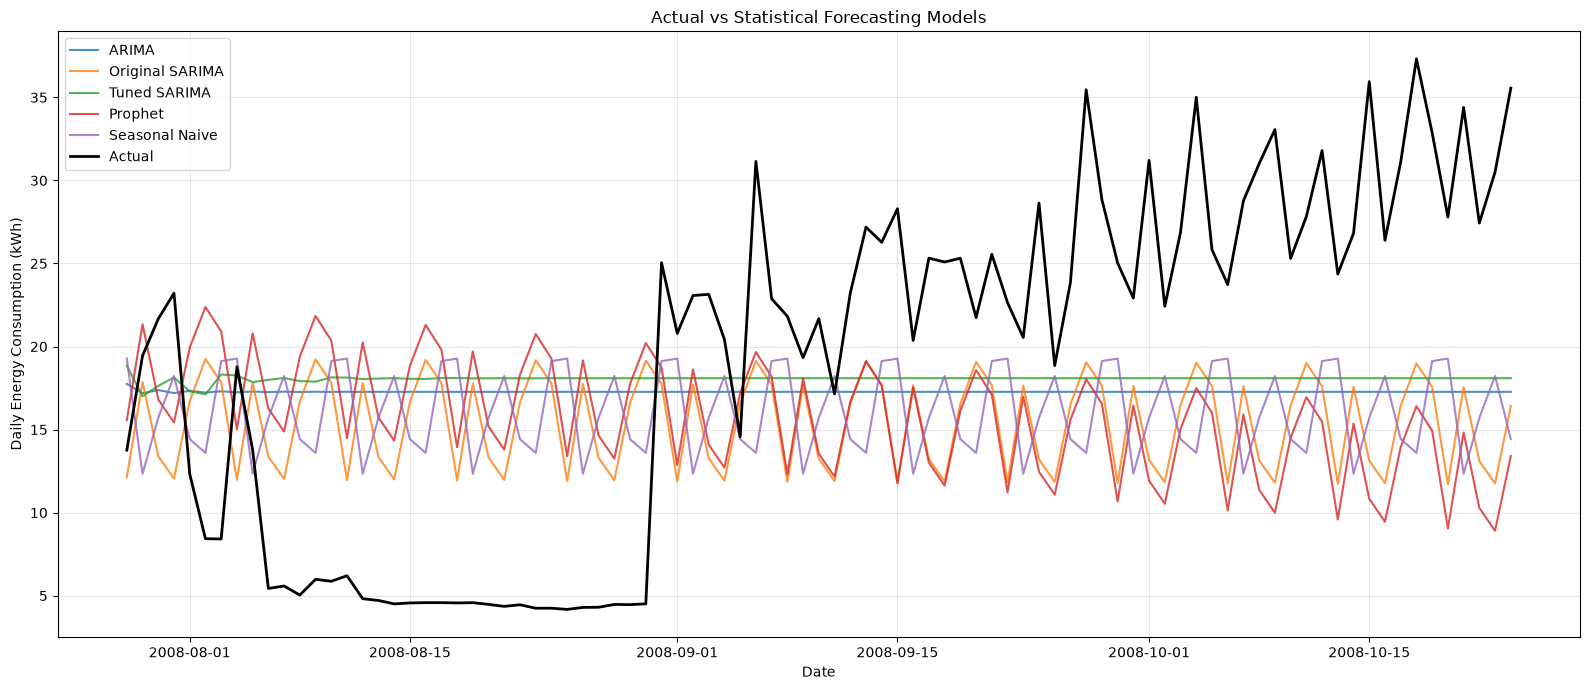

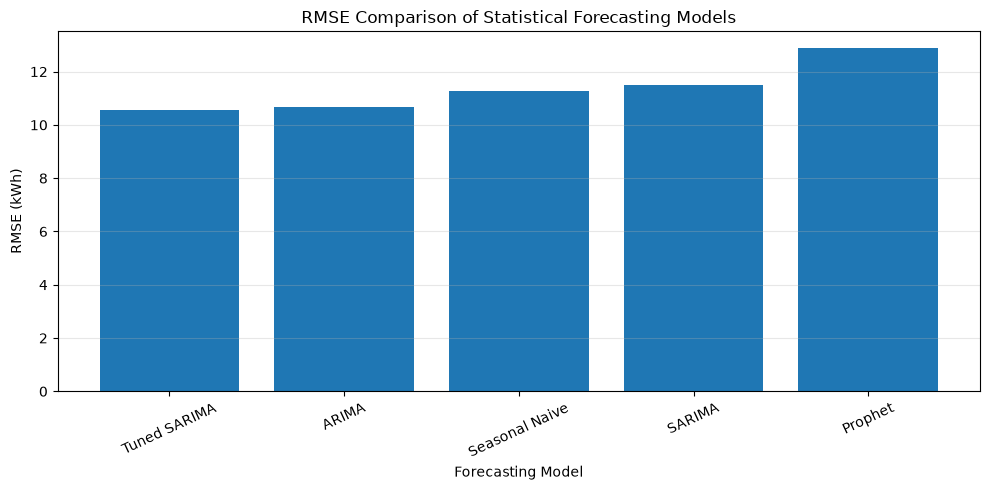

Final statistical comparison graphs generated successfully!


In [106]:
# CELL 17: Final statistical forecasting comparison

final_forecasts = pd.DataFrame({
    "Actual": test,
    "ARIMA": arima_forecast,
    "Original SARIMA": sarima_forecast,
    "Tuned SARIMA": tuned_sarima_forecast,
    "Prophet": prophet_forecast,
    "Seasonal Naive": seasonal_naive_forecast
})

# Plot actual vs predicted
plt.figure(figsize=(16, 7))

for column in final_forecasts.columns:
    if column != "Actual":
        plt.plot(
            final_forecasts.index,
            final_forecasts[column],
            label=column,
            alpha=0.8
        )

plt.plot(
    final_forecasts.index,
    final_forecasts["Actual"],
    label="Actual",
    color="black",
    linewidth=2
)

plt.title("Actual vs Statistical Forecasting Models")
plt.xlabel("Date")
plt.ylabel("Daily Energy Consumption (kWh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "final_statistical_forecast_comparison.png"),
    dpi=300
)

plt.show()

# RMSE comparison chart
plt.figure(figsize=(10, 5))

plot_metrics = updated_metrics.sort_values("RMSE")

plt.bar(
    plot_metrics.index,
    plot_metrics["RMSE"]
)

plt.title("RMSE Comparison of Statistical Forecasting Models")
plt.xlabel("Forecasting Model")
plt.ylabel("RMSE (kWh)")
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "statistical_rmse_comparison.png"),
    dpi=300
)

plt.show()

print("Final statistical comparison graphs generated successfully!")


In [107]:
# CELL 18: Save final Task 1 report

final_report = pd.DataFrame({
    "Model": updated_metrics.index,
    "MAE": updated_metrics["MAE"].values,
    "MSE": updated_metrics["MSE"].values,
    "RMSE": updated_metrics["RMSE"].values,
    "R2": updated_metrics["R2"].values,
    "MAPE (%)": updated_metrics["MAPE (%)"].values
})

final_report = final_report.sort_values("RMSE")

final_report.to_csv(
    os.path.join(OUTPUT_DIR, "task1_final_results.csv"),
    index=False
)

# Save actual and predicted values
final_forecasts.to_csv(
    os.path.join(OUTPUT_DIR, "task1_all_forecasts.csv")
)

print("=" * 55)
print("TASK 1: TIME-SERIES FORECASTING - FINAL REPORT")
print("=" * 55)

display(final_report.round(4))

print("\nBest model by RMSE:", final_report.iloc[0]["Model"])
print("Best RMSE:", round(final_report.iloc[0]["RMSE"], 4))

print("\nResidual diagnostics:")
print("Ljung-Box indicates remaining autocorrelation.")
print("Jarque-Bera p-value:", round(jb_pvalue, 4))

print("\nTask 1 outputs saved successfully!")
print("Evaluation folder:", OUTPUT_DIR)
print("Visualization folder:", PLOT_DIR)


TASK 1: TIME-SERIES FORECASTING - FINAL REPORT


,Model,MAE,MSE,RMSE,R2,MAPE (%)
0,Tuned SARIMA,9.4488,111.1641,10.5434,-0.0085,102.6250
1,ARIMA,9.6891,113.9687,10.6756,-0.0340,99.4544
2,Seasonal Naive,9.9809,126.7805,11.2597,-0.1502,93.7508
3,SARIMA,10.5337,132.2065,11.4981,-0.1994,94.5951
4,Prophet,11.7434,165.6059,12.8688,-0.5025,109.2022



Best model by RMSE: Tuned SARIMA
Best RMSE: 10.5434

Residual diagnostics:
Ljung-Box indicates remaining autocorrelation.
Jarque-Bera p-value: 0.4378

Task 1 outputs saved successfully!
Evaluation folder: ../evaluation/advanced_forecasting
Visualization folder: ../visualizations/advanced_forecasting


In [108]:
# CELL 19: Prepare hourly time-series data for LSTM

import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from datetime import timedelta

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Use hourly energy consumption
hourly_series = df["Energy_kWh"].copy().sort_index()

# Validate timestamps
if hourly_series.index.has_duplicates:
    raise ValueError("Duplicate timestamps found.")

if hourly_series.isna().any():
    raise ValueError("Missing energy values found.")

# Sequence configuration
LOOKBACK = 168  # Previous 7 days
TRAIN_RATIO = 0.80

# Chronological cutoff based on available hourly observations
split_position = int(len(hourly_series) * TRAIN_RATIO)
split_timestamp = hourly_series.index[split_position]

# Fit scaler ONLY on training observations
scaler = MinMaxScaler(feature_range=(0, 1))

scaler.fit(
    hourly_series.loc[hourly_series.index < split_timestamp]
    .to_numpy()
    .reshape(-1, 1)
)

scaled_values = scaler.transform(
    hourly_series.to_numpy().reshape(-1, 1)
).flatten()

# Identify continuous hourly segments
time_difference = hourly_series.index.to_series().diff()

segment_ids = (
    time_difference.ne(pd.Timedelta(hours=1))
    .cumsum()
    .to_numpy()
)

X_train, y_train = [], []
X_test, y_test = [], []

train_target_times = []
test_target_times = []

# Generate sequences without crossing missing-hour gaps
for segment_id in np.unique(segment_ids):

    positions = np.where(segment_ids == segment_id)[0]

    if len(positions) <= LOOKBACK:
        continue

    segment_values = scaled_values[positions]
    segment_times = hourly_series.index[positions]

    for i in range(LOOKBACK, len(segment_values)):

        sequence = segment_values[i - LOOKBACK:i]
        target = segment_values[i]
        target_time = segment_times[i]

        if target_time < split_timestamp:
            X_train.append(sequence)
            y_train.append(target)
            train_target_times.append(target_time)
        else:
            X_test.append(sequence)
            y_test.append(target)
            test_target_times.append(target_time)

# Convert to NumPy arrays
X_train = np.asarray(X_train, dtype=np.float32)
y_train = np.asarray(y_train, dtype=np.float32)

X_test = np.asarray(X_test, dtype=np.float32)
y_test = np.asarray(y_test, dtype=np.float32)

# Add LSTM feature dimension
X_train = X_train.reshape(-1, LOOKBACK, 1)
X_test = X_test.reshape(-1, LOOKBACK, 1)

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("Insufficient sequences for training or testing.")

print("LSTM DATA PREPARATION COMPLETED")
print("=" * 45)
print("Lookback window:", LOOKBACK, "hours")
print("Training cutoff:", split_timestamp)
print("Training sequences:", X_train.shape)
print("Testing sequences:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

print("\nTraining target period:",
      min(train_target_times), "to", max(train_target_times))

print("Testing target period:",
      min(test_target_times), "to", max(test_target_times))

assert max(train_target_times) < min(test_target_times)


LSTM DATA PREPARATION COMPLETED
Lookback window: 168 hours
Training cutoff: 2010-02-06 20:00:00
Training sequences: (23126, 168, 1)
Testing sequences: (5782, 168, 1)
Training targets: (23126,)
Testing targets: (5782,)

Training target period: 2007-01-08 00:00:00 to 2010-02-06 19:00:00
Testing target period: 2010-02-06 20:00:00 to 2010-11-26 20:00:00


In [109]:
# CELL 20: Build and compile the LSTM model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

lstm_model = Sequential([
    Input(shape=(LOOKBACK, 1)),

    LSTM(64, return_sequences=True),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1)
])

lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)

print("LSTM MODEL CREATED")
print("=" * 40)

lstm_model.summary()

LSTM MODEL CREATED


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_8 (LSTM)                   │ (None, 168, 64)        │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 168, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [110]:
# CELL 21: Train the LSTM model

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.15,
    callbacks=[early_stopping],
    shuffle=False,
    verbose=1
)

print("\nLSTM TRAINING COMPLETED")
print("=" * 40)
print("Epochs trained:", len(history.history["loss"]))
print("Best validation loss:",
      min(history.history["val_loss"]))


Epoch 1/30
308/308 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step - loss: 0.0178 - mean_absolute_error: 0.1017 - val_loss: 0.0234 - val_mean_absolute_error: 0.1076
Epoch 2/30
308/308 ━━━━━━━━━━━━━━━━━━━━ 17s 55ms/step - loss: 0.0121 - mean_absolute_error: 0.0807 - val_loss: 0.0155 - val_mean_absolute_error: 0.0849
Epoch 3/30
308/308 ━━━━━━━━━━━━━━━━━━━━ 18s 57ms/step - loss: 0.0106 - mean_absolute_error: 0.0735 - val_loss: 0.0149 - val_mean_absolute_error: 0.0829
Epoch 4/30
308/308 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - loss: 0.0103 - mean_absolute_error: 0.0717 - val_loss: 0.0143 - val_mean_absolute_error: 0.0813
Epoch 5/30
308/308 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - loss: 0.0099 - mean_absolute_error: 0.0699 - val_loss: 0.0134 - val_mean_absolute_error: 0.0792
Epoch 6/30
308/308 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - loss: 0.0098 - mean_absolute_error: 0.0690 - val_loss: 0.0136 - val_mean_absolute_error: 0.0786
Epoch 7/30
308/308 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - loss: 0.0096 - mean_absolute_err

In [111]:
# CELL 22: Predict and evaluate LSTM model

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Step 1: Predict
y_pred_scaled = lstm_model.predict(X_test, verbose=1)

# Step 2: Convert scaled values back to original values
y_pred = scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).flatten()

y_actual = scaler.inverse_transform(
    np.asarray(y_test).reshape(-1, 1)
).flatten()

# Step 3: Calculate evaluation metrics
lstm_mae = mean_absolute_error(y_actual, y_pred)
lstm_mse = mean_squared_error(y_actual, y_pred)
lstm_rmse = np.sqrt(lstm_mse)
lstm_r2 = r2_score(y_actual, y_pred)

# Step 4: Calculate MAPE
nonzero_mask = y_actual != 0

lstm_mape = np.mean(
    np.abs(
        (y_actual[nonzero_mask] - y_pred[nonzero_mask])
        / y_actual[nonzero_mask]
    )
) * 100

# Step 5: Calculate WAPE
total_actual = np.sum(np.abs(y_actual))

lstm_wape = (
    np.sum(np.abs(y_actual - y_pred)) / total_actual * 100
    if total_actual != 0 else np.nan
)

# Step 6: Calculate sMAPE
denominator = np.abs(y_actual) + np.abs(y_pred)

valid_mask = denominator != 0

lstm_smape = np.mean(
    2 * np.abs(y_actual[valid_mask] - y_pred[valid_mask])
    / denominator[valid_mask]
) * 100

# Step 7: Display results
lstm_metrics = pd.DataFrame([{
    "Model": "LSTM",
    "MAE": lstm_mae,
    "MSE": lstm_mse,
    "RMSE": lstm_rmse,
    "R2": lstm_r2,
    "MAPE (%)": lstm_mape,
    "WAPE (%)": lstm_wape,
    "sMAPE (%)": lstm_smape
}])

display(lstm_metrics)

# Step 8: Save predictions
lstm_predictions = pd.DataFrame({
    "Timestamp": test_target_times,
    "Actual_Energy_kWh": y_actual,
    "Predicted_Energy_kWh": y_pred
})

display(lstm_predictions.head())

181/181 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step


,Model,MAE,MSE,RMSE,R2,MAPE (%),WAPE (%),sMAPE (%)
0,LSTM,0.375068,0.322825,0.568177,0.413321,36.483353,37.598713,37.580784


,Timestamp,Actual_Energy_kWh,Predicted_Energy_kWh
0,2010-02-06 20:00:00,2.558233,2.197294
1,2010-02-06 21:00:00,2.988300,1.622342
2,2010-02-06 22:00:00,2.849100,1.900560
3,2010-02-06 23:00:00,3.474900,1.693631
4,2010-02-07 00:00:00,1.058700,2.000843


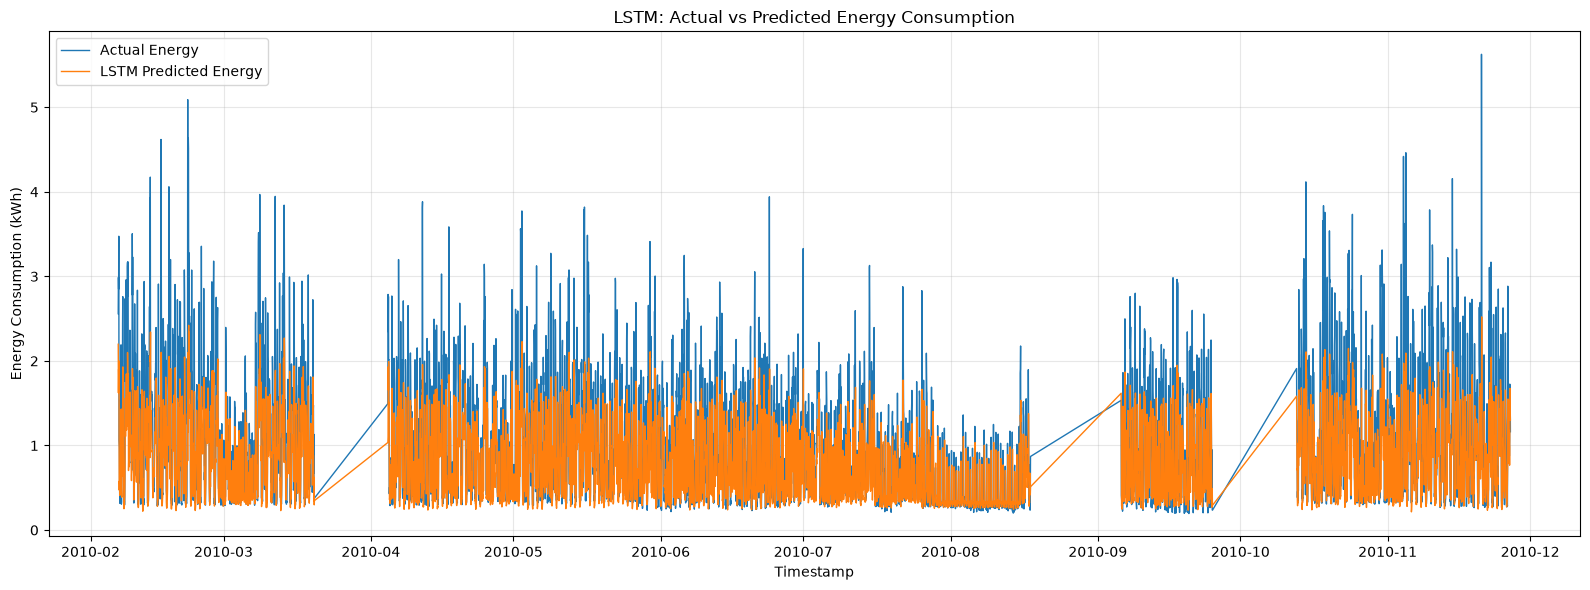

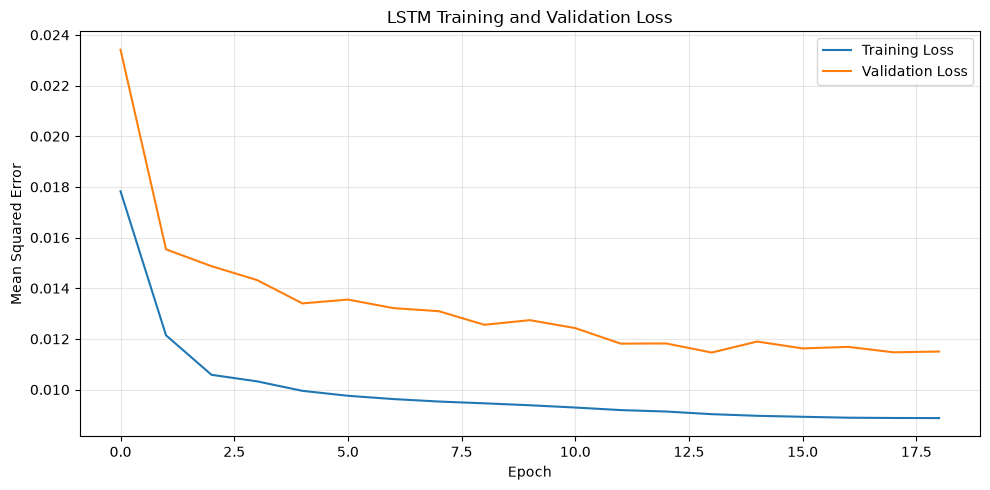

LSTM VISUALIZATIONS COMPLETED
Saved files:
1. lstm_actual_vs_predicted.png
2. lstm_training_validation_loss.png

Visualization directory:
c:\Users\vyshu\OneDrive\Desktop\Smart-Energy-Forecasting\visualizations\advanced_forecasting

CELL 23 COMPLETED SUCCESSFULLY


In [125]:
# CELL 23: Visualize LSTM Training and Predictions

import os
import matplotlib.pyplot as plt

# Step 1: Create visualization directory
visualization_dir = os.path.abspath(
    os.path.join("..", "visualizations", "advanced_forecasting")
)

os.makedirs(visualization_dir, exist_ok=True)


# ============================================================
# PLOT 1: ACTUAL VS PREDICTED ENERGY CONSUMPTION
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    lstm_predictions["Timestamp"],
    lstm_predictions["Actual_Energy_kWh"],
    label="Actual Energy",
    linewidth=1
)

plt.plot(
    lstm_predictions["Timestamp"],
    lstm_predictions["Predicted_Energy_kWh"],
    label="LSTM Predicted Energy",
    linewidth=1
)

plt.title("LSTM: Actual vs Predicted Energy Consumption")
plt.xlabel("Timestamp")
plt.ylabel("Energy Consumption (kWh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        visualization_dir,
        "lstm_actual_vs_predicted.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# PLOT 2: TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        visualization_dir,
        "lstm_training_validation_loss.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# COMPLETION MESSAGE
# ============================================================

print("LSTM VISUALIZATIONS COMPLETED")
print("=" * 50)

print("Saved files:")
print("1. lstm_actual_vs_predicted.png")
print("2. lstm_training_validation_loss.png")

print("\nVisualization directory:")
print(visualization_dir)

print("\nCELL 23 COMPLETED SUCCESSFULLY")


In [113]:
# CELL 24: Save LSTM model, predictions and evaluation results

import os
import joblib

# Create output directories
model_dir = "../models"
evaluation_dir = "../evaluation/advanced_forecasting"
visualization_dir = "../visualizations/advanced_forecasting"

os.makedirs(model_dir, exist_ok=True)
os.makedirs(evaluation_dir, exist_ok=True)
os.makedirs(visualization_dir, exist_ok=True)

# Save trained LSTM model
lstm_model.save(
    os.path.join(model_dir, "lstm_energy_model.keras")
)

# Save fitted scaler
joblib.dump(
    scaler,
    os.path.join(model_dir, "lstm_scaler.pkl")
)

# Save predictions
lstm_predictions.to_csv(
    os.path.join(evaluation_dir, "lstm_predictions.csv"),
    index=False
)

# Save evaluation metrics
lstm_metrics.to_csv(
    os.path.join(evaluation_dir, "lstm_metrics.csv"),
    index=False
)

# Save training history
training_history = pd.DataFrame({
    "Epoch": range(1, len(history.history["loss"]) + 1),
    "Training_Loss": history.history["loss"],
    "Validation_Loss": history.history["val_loss"]
})

training_history.to_csv(
    os.path.join(evaluation_dir, "lstm_training_history.csv"),
    index=False
)

print("LSTM FILES SAVED SUCCESSFULLY")
print("=" * 45)

print("Model: models/lstm_energy_model.keras")
print("Scaler: models/lstm_scaler.pkl")
print("Predictions: evaluation/advanced_forecasting/lstm_predictions.csv")
print("Metrics: evaluation/advanced_forecasting/lstm_metrics.csv")
print("Training history: evaluation/advanced_forecasting/lstm_training_history.csv")


LSTM FILES SAVED SUCCESSFULLY
Model: models/lstm_energy_model.keras
Scaler: models/lstm_scaler.pkl
Predictions: evaluation/advanced_forecasting/lstm_predictions.csv
Metrics: evaluation/advanced_forecasting/lstm_metrics.csv
Training history: evaluation/advanced_forecasting/lstm_training_history.csv


In [114]:
# CELL 25: Download historical weather data for Sceaux, France

import requests
import os
import pandas as pd
import numpy as np

# Sceaux, France coordinates
LATITUDE = 48.7786
LONGITUDE = 2.2906

START_DATE = "2007-01-01"
END_DATE = "2010-11-26"

WEATHER_DIR = "../dataset"
os.makedirs(WEATHER_DIR, exist_ok=True)

API_URL = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": LATITUDE,
    "longitude": LONGITUDE,
    "start_date": START_DATE,
    "end_date": END_DATE,
    "hourly": "temperature_2m,relative_humidity_2m",
    "timezone": "Europe/Paris",
    "temperature_unit": "celsius",
    "models": "era5_land"
}

print("Downloading historical weather data...")
print("Location: Sceaux, France")
print("Period:", START_DATE, "to", END_DATE)

response = requests.get(
    API_URL,
    params=params,
    timeout=120
)

response.raise_for_status()

weather_data = response.json()

if "hourly" not in weather_data:
    raise ValueError(
        "Hourly weather data not found in API response."
    )

# Create weather DataFrame
weather_df = pd.DataFrame({
    "Timestamp": weather_data["hourly"]["time"],
    "Temperature_C": weather_data["hourly"]["temperature_2m"],
    "Humidity_Percent": weather_data["hourly"]["relative_humidity_2m"]
})

# Convert timestamps
weather_df["Timestamp"] = pd.to_datetime(
    weather_df["Timestamp"]
)

# Set timestamp as index
weather_df = weather_df.set_index("Timestamp").sort_index()

# Validate downloaded data
print("\nWEATHER DATA DOWNLOADED")
print("=" * 45)

print("Shape:", weather_df.shape)
print("Date range:", weather_df.index.min(),
      "to", weather_df.index.max())

print("Duplicate timestamps:",
      weather_df.index.has_duplicates)

print("\nMissing values:")
print(weather_df.isna().sum())

print("\nWeather data sample:")
display(weather_df.head())

# Save original downloaded weather data
weather_path = os.path.join(
    WEATHER_DIR,
    "historical_weather_sceaux.csv"
)

weather_df.to_csv(weather_path)

print("\nWeather data saved to:", weather_path)


Location: Sceaux, France
Period: 2007-01-01 to 2010-11-26

WEATHER DATA DOWNLOADED
Shape: (34224, 2)
Date range: 2007-01-01 00:00:00 to 2010-11-26 23:00:00
Duplicate timestamps: False

Missing values:
Temperature_C       0
Humidity_Percent    0
dtype: int64

Weather data sample:


,Temperature_C,Humidity_Percent
Timestamp,,
2007-01-01 00:00:00,12.4,92
2007-01-01 01:00:00,12.3,92
2007-01-01 02:00:00,12.2,93
2007-01-01 03:00:00,11.8,92
2007-01-01 04:00:00,11.3,87



Weather data saved to: ../dataset\historical_weather_sceaux.csv


In [115]:
# CELL 26: Merge hourly energy and weather datasets

# Keep only the required energy column
energy_df = df[["Energy_kWh"]].copy()

# Ensure both datasets use sorted datetime indexes
energy_df = energy_df.sort_index()
weather_df = weather_df.sort_index()

# Merge using exact timestamps
weather_energy_df = energy_df.join(
    weather_df,
    how="inner"
)

# Validate merged dataset
print("ENERGY + WEATHER DATA MERGED")
print("=" * 50)

print("Original energy records:", len(energy_df))
print("Original weather records:", len(weather_df))
print("Merged records:", len(weather_energy_df))

print("\nMerged date range:")
print(weather_energy_df.index.min(),
      "to",
      weather_energy_df.index.max())

print("\nMissing values:")
print(weather_energy_df.isna().sum())

print("\nDuplicate timestamps:",
      weather_energy_df.index.has_duplicates)

print("\nDataset sample:")
display(weather_energy_df.head())

# Save merged dataset
merged_path = os.path.join(
    WEATHER_DIR,
    "energy_weather_merged.csv"
)

weather_energy_df.to_csv(merged_path)

print("\nMerged dataset saved to:", merged_path)

# Basic validation
assert not weather_energy_df.index.has_duplicates
assert weather_energy_df.isna().sum().sum() == 0
assert len(weather_energy_df) > 0

print("\nMERGE VALIDATION PASSED")


ENERGY + WEATHER DATA MERGED
Original energy records: 31428
Original weather records: 34224
Merged records: 31428

Merged date range:
2007-01-01 00:00:00 to 2010-11-26 20:00:00

Missing values:
Energy_kWh          0
Temperature_C       0
Humidity_Percent    0
dtype: int64

Duplicate timestamps: False

Dataset sample:


,Energy_kWh,Temperature_C,Humidity_Percent
DateTime,,,
2007-01-01 00:00:00,2.550633,12.4,92
2007-01-01 01:00:00,2.523400,12.3,92
2007-01-01 02:00:00,2.582333,12.2,93
2007-01-01 03:00:00,2.541667,11.8,92
2007-01-01 04:00:00,2.475733,11.3,87



Merged dataset saved to: ../dataset\energy_weather_merged.csv

MERGE VALIDATION PASSED


CORRELATION MATRIX


,Energy_kWh,Temperature_C,Humidity_Percent
Energy_kWh,1.000,-0.179,0.050
Temperature_C,-0.179,1.000,-0.554
Humidity_Percent,0.050,-0.554,1.000


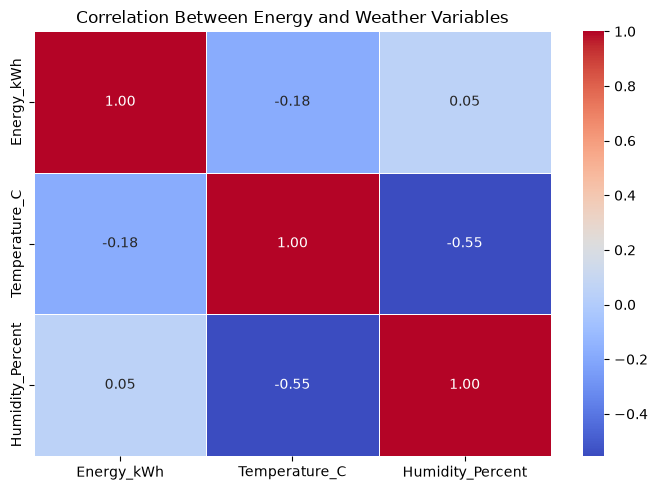

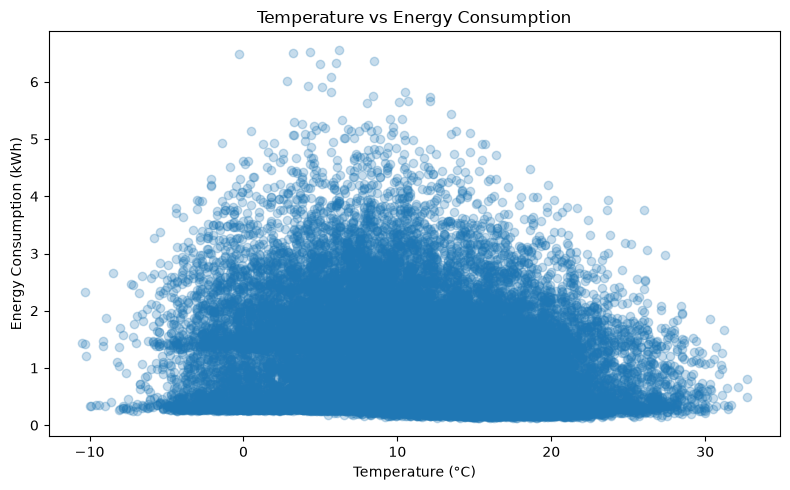

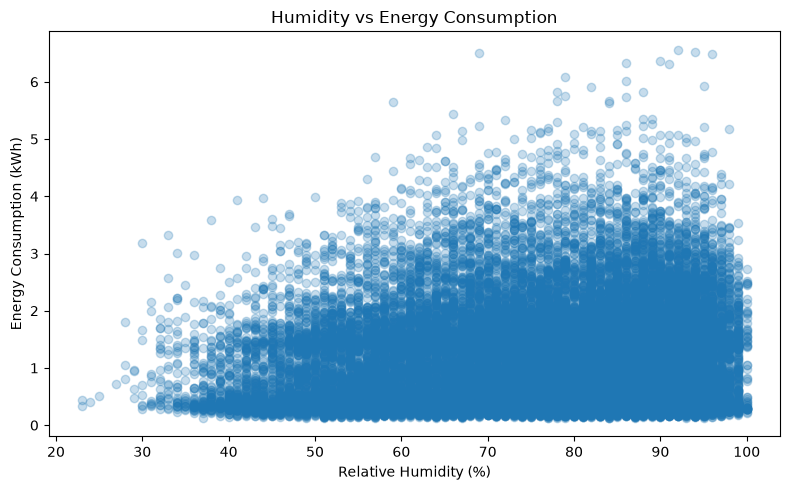

WEATHER EXPLORATORY ANALYSIS COMPLETED


In [116]:
# CELL 27: Exploratory Analysis of Weather and Energy Consumption

import matplotlib.pyplot as plt
import seaborn as sns

# Correlation analysis
correlation = weather_energy_df[
    ["Energy_kWh", "Temperature_C", "Humidity_Percent"]
].corr()

print("CORRELATION MATRIX")
display(correlation.round(3))

# Correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Between Energy and Weather Variables")
plt.tight_layout()
plt.show()

# Temperature vs Energy
plt.figure(figsize=(8, 5))
plt.scatter(
    weather_energy_df["Temperature_C"],
    weather_energy_df["Energy_kWh"],
    alpha=0.25
)
plt.xlabel("Temperature (°C)")
plt.ylabel("Energy Consumption (kWh)")
plt.title("Temperature vs Energy Consumption")
plt.tight_layout()
plt.show()

# Humidity vs Energy
plt.figure(figsize=(8, 5))
plt.scatter(
    weather_energy_df["Humidity_Percent"],
    weather_energy_df["Energy_kWh"],
    alpha=0.25
)
plt.xlabel("Relative Humidity (%)")
plt.ylabel("Energy Consumption (kWh)")
plt.title("Humidity vs Energy Consumption")
plt.tight_layout()
plt.show()

print("WEATHER EXPLORATORY ANALYSIS COMPLETED")

In [117]:
# CELL 28: Feature Engineering and Chronological Train-Test Split

import numpy as np
import pandas as pd

# Step 1: Prepare dataset
model_df = weather_energy_df.copy().sort_index()

# Validate timestamp index
if not isinstance(model_df.index, pd.DatetimeIndex):
    raise TypeError("Dataset must have a DatetimeIndex.")

if model_df.index.has_duplicates:
    raise ValueError("Duplicate timestamps found!")

required_source_columns = [
    "Energy_kWh",
    "Temperature_C",
    "Humidity_Percent"
]

missing_columns = [
    col for col in required_source_columns
    if col not in model_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Step 2: Create continuous hourly timeline
full_index = pd.date_range(
    start=model_df.index.min(),
    end=model_df.index.max(),
    freq="h"
)

model_df = model_df.reindex(full_index)
model_df.index.name = "DateTime"

# Step 3: Calendar features
model_df["Hour"] = model_df.index.hour
model_df["DayOfWeek"] = model_df.index.day_of_week
model_df["Month"] = model_df.index.month

# Step 4: Cyclical time features
model_df["Hour_sin"] = np.sin(
    2 * np.pi * model_df["Hour"] / 24
)

model_df["Hour_cos"] = np.cos(
    2 * np.pi * model_df["Hour"] / 24
)

model_df["Day_sin"] = np.sin(
    2 * np.pi * model_df["DayOfWeek"] / 7
)

model_df["Day_cos"] = np.cos(
    2 * np.pi * model_df["DayOfWeek"] / 7
)

# Step 5: Historical energy lag features
for lag in [1, 24, 168]:
    model_df[f"Energy_lag_{lag}"] = (
        model_df["Energy_kWh"].shift(lag)
    )

# Step 6: Define feature groups
baseline_features = [
    "Hour_sin",
    "Hour_cos",
    "Day_sin",
    "Day_cos",
    "Month",
    "Energy_lag_1",
    "Energy_lag_24",
    "Energy_lag_168"
]

weather_features = baseline_features + [
    "Temperature_C",
    "Humidity_Percent"
]

# Step 7: Remove rows with missing target,
# lag values, or weather measurements.
required_features = weather_features + ["Energy_kWh"]

model_df = model_df.dropna(
    subset=required_features
).copy()

# Validate prepared data
if model_df.empty:
    raise ValueError(
        "No usable records remain after removing missing values."
    )

assert model_df.index.is_monotonic_increasing
assert not model_df.index.has_duplicates

assert np.isfinite(
    model_df[required_features].to_numpy(dtype=float)
).all()

# Step 8: Prepare X and y
X_baseline = model_df[baseline_features]
X_weather = model_df[weather_features]

y = model_df["Energy_kWh"]

# Step 9: Chronological 80:20 split
split_index = int(len(model_df) * 0.80)

if split_index <= 0 or split_index >= len(model_df):
    raise ValueError("Insufficient records for train-test split.")

X_train_base = X_baseline.iloc[:split_index].copy()
X_test_base = X_baseline.iloc[split_index:].copy()

X_train_weather = X_weather.iloc[:split_index].copy()
X_test_weather = X_weather.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

# Step 10: Validate split
assert X_train_base.index.equals(y_train.index)
assert X_test_base.index.equals(y_test.index)

assert X_train_weather.index.equals(y_train.index)
assert X_test_weather.index.equals(y_test.index)

assert X_train_base.index.max() < X_test_base.index.min()

# Display results
print("=" * 65)
print("WEATHER FEATURE ENGINEERING AND DATA SPLIT")
print("=" * 65)

print("Usable records:", len(model_df))
print("Baseline features:", len(baseline_features))
print("Weather features:", len(weather_features))

print("\nTraining records:", len(y_train))
print("Testing records:", len(y_test))

print("\nTraining period:")
print(y_train.index.min(), "to", y_train.index.max())

print("\nTesting period:")
print(y_test.index.min(), "to", y_test.index.max())

print("\nMissing values:")
display(model_df[required_features].isna().sum())

print("\nChronological split validation passed!")
print("Feature engineering completed successfully.")

WEATHER FEATURE ENGINEERING AND DATA SPLIT
Usable records: 28908
Baseline features: 8
Weather features: 10

Training records: 23126
Testing records: 5782

Training period:
2007-01-08 00:00:00 to 2010-02-06 19:00:00

Testing period:
2010-02-06 20:00:00 to 2010-11-26 20:00:00

Missing values:


Hour_sin            0
Hour_cos            0
Day_sin             0
Day_cos             0
Month               0
Energy_lag_1        0
Energy_lag_24       0
Energy_lag_168      0
Temperature_C       0
Humidity_Percent    0
Energy_kWh          0
dtype: int64


Chronological split validation passed!
Feature engineering completed successfully.


In [118]:
# CELL 29: Train Baseline and Weather-Based Models

import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Step 1: Initialize baseline model
baseline_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Step 2: Initialize weather model
weather_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Step 3: Train baseline model
print("Training Baseline Model...")

start_time = time.time()

baseline_model.fit(X_train_base, y_train)

baseline_time = time.time() - start_time

# Step 4: Train weather model
print("\nTraining Weather-Based Model...")

start_time = time.time()

weather_model.fit(X_train_weather, y_train)

weather_time = time.time() - start_time

# Step 5: Generate predictions
baseline_predictions = baseline_model.predict(X_test_base)

weather_predictions = weather_model.predict(X_test_weather)

# Step 6: Evaluation function
def evaluate_model(name, actual, predicted):

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    total_actual = np.sum(np.abs(actual))

    wape = (
        np.sum(np.abs(actual - predicted))
        / total_actual * 100
        if total_actual != 0
        else np.nan
    )

    denominator = np.abs(actual) + np.abs(predicted)
    valid = denominator != 0

    smape = (
        np.mean(
            2 * np.abs(actual[valid] - predicted[valid])
            / denominator[valid]
        ) * 100
        if valid.any()
        else np.nan
    )

    return {
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "WAPE (%)": wape,
        "sMAPE (%)": smape
    }

# Step 7: Compare models
weather_results = pd.DataFrame([
    evaluate_model(
        "Baseline (Without Weather)",
        y_test,
        baseline_predictions
    ),
    evaluate_model(
        "Weather-Based Model",
        y_test,
        weather_predictions
    )
])

# Step 8: Validate predictions
assert len(baseline_predictions) == len(y_test)
assert len(weather_predictions) == len(y_test)

assert np.isfinite(baseline_predictions).all()
assert np.isfinite(weather_predictions).all()

print("\n" + "=" * 65)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 65)

display(weather_results.round(4))

print("\nBaseline training time:",
      round(baseline_time, 2), "seconds")

print("Weather model training time:",
      round(weather_time, 2), "seconds")

print("\nEVALUATION METHODOLOGY")
print(
    "Rolling one-step-ahead evaluation using actual "
    "previously observed energy readings."
)

print(
    "The weather model uses historical observed weather "
    "measurements at each prediction timestamp."
)

print(
    "For real future forecasting, weather forecast inputs "
    "must replace observed future weather."
)

print("\nModel training and evaluation completed!")

Training Baseline Model...

Training Weather-Based Model...

MODEL PERFORMANCE COMPARISON


,Model,MAE,MSE,RMSE,R2,WAPE (%),sMAPE (%)
0,Baseline (Without Weather),0.3421,0.2456,0.4956,0.5536,34.2982,35.3546
1,Weather-Based Model,0.3418,0.2440,0.4939,0.5566,34.2601,35.3931



Baseline training time: 0.53 seconds
Weather model training time: 0.65 seconds

EVALUATION METHODOLOGY
Rolling one-step-ahead evaluation using actual previously observed energy readings.
The weather model uses historical observed weather measurements at each prediction timestamp.
For real future forecasting, weather forecast inputs must replace observed future weather.

Model training and evaluation completed!


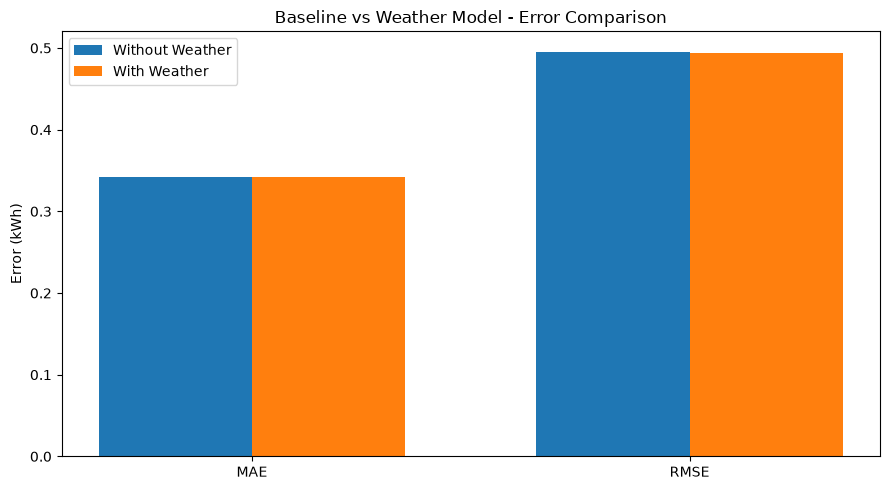

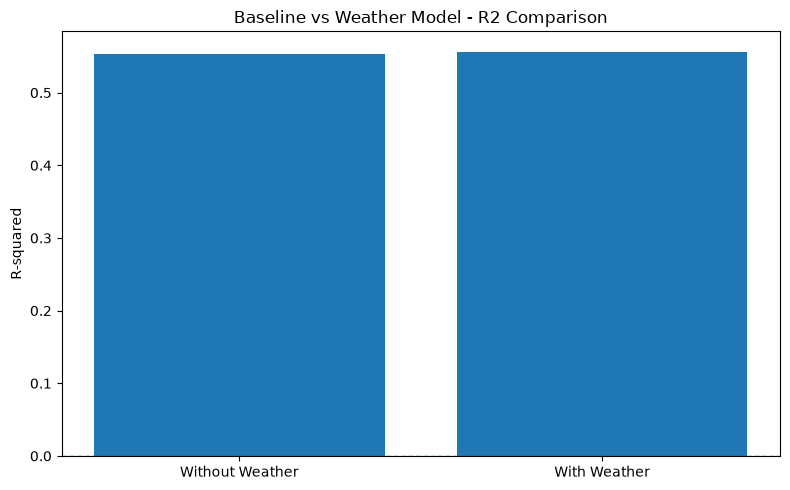

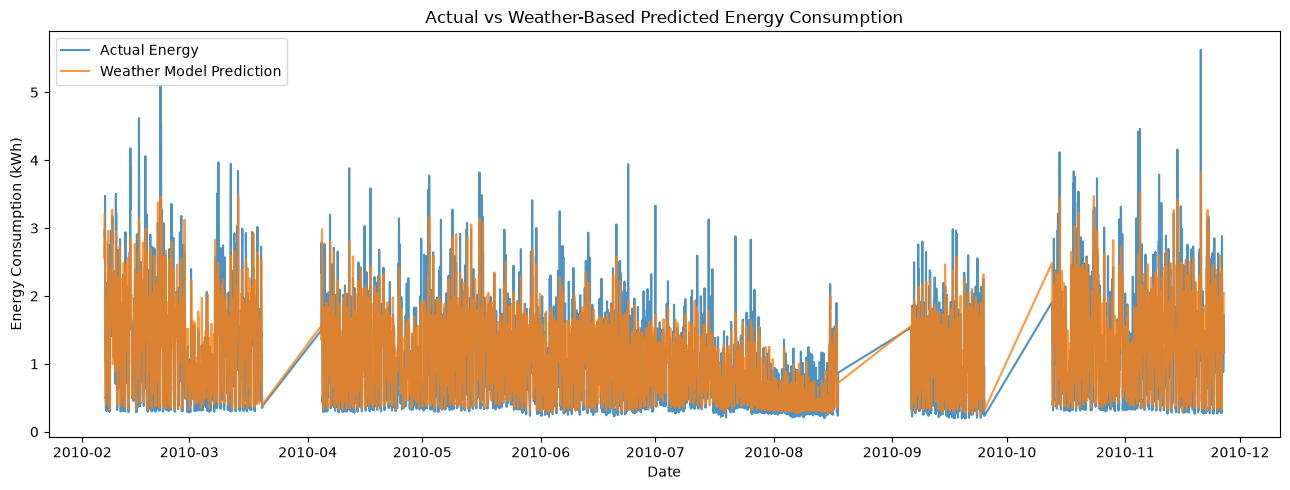

MODEL COMPARISON VISUALIZATION COMPLETED


In [119]:
# CELL 30: Visual Comparison of Baseline and Weather Models

import matplotlib.pyplot as plt
import numpy as np

# Step 1: Extract results
baseline_result = weather_results.iloc[0]
weather_result = weather_results.iloc[1]

# Step 2: Compare error metrics
error_metrics = ["MAE", "RMSE"]

baseline_errors = [
    baseline_result[metric]
    for metric in error_metrics
]

weather_errors = [
    weather_result[metric]
    for metric in error_metrics
]

x = np.arange(len(error_metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    baseline_errors,
    width,
    label="Without Weather"
)

plt.bar(
    x + width / 2,
    weather_errors,
    width,
    label="With Weather"
)

plt.xticks(x, error_metrics)
plt.ylabel("Error (kWh)")
plt.title("Baseline vs Weather Model - Error Comparison")
plt.legend()
plt.tight_layout()
plt.show()

# Step 3: Compare R2 separately
r2_values = [
    baseline_result["R2"],
    weather_result["R2"]
]

model_names = [
    "Without Weather",
    "With Weather"
]

plt.figure(figsize=(8, 5))

plt.bar(
    model_names,
    r2_values
)

plt.ylabel("R-squared")
plt.title("Baseline vs Weather Model - R2 Comparison")
plt.axhline(y=0, linestyle="--", linewidth=1)

plt.tight_layout()
plt.show()

# Step 4: Actual vs predicted values
plt.figure(figsize=(13, 5))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual Energy",
    alpha=0.8
)

plt.plot(
    y_test.index,
    weather_predictions,
    label="Weather Model Prediction",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("Energy Consumption (kWh)")
plt.title("Actual vs Weather-Based Predicted Energy Consumption")
plt.legend()
plt.tight_layout()
plt.show()

print("MODEL COMPARISON VISUALIZATION COMPLETED")

WEATHER MODEL FEATURE IMPORTANCE


,Feature,Importance
0,Energy_lag_1,0.6258
1,Energy_lag_168,0.0820
2,Energy_lag_24,0.0624
3,Hour_cos,0.0503
4,Hour_sin,0.0496
5,Temperature_C,0.0447
6,Humidity_Percent,0.0353
7,Day_sin,0.0224
8,Month,0.0194
9,Day_cos,0.0081


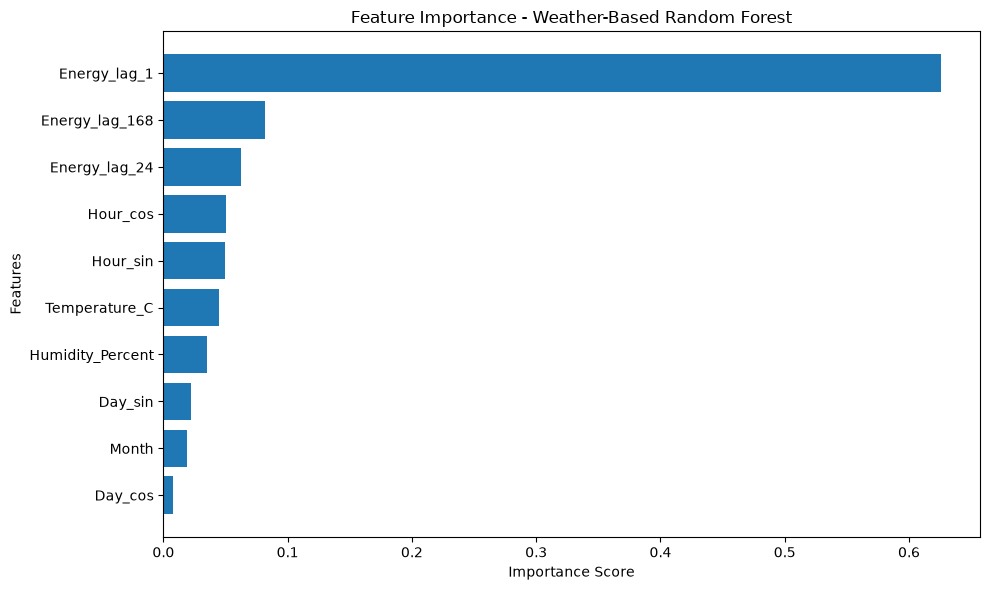


Feature importance saved successfully!
File location: c:\Users\vyshu\OneDrive\Desktop\Smart-Energy-Forecasting\evaluation\weather_forecasting\weather_feature_importance.csv

CELL 31 COMPLETED SUCCESSFULLY


In [120]:
# CELL 31: Weather Model Feature Importance

import os
import matplotlib.pyplot as plt
import pandas as pd

# Create evaluation directory
EVALUATION_DIR = os.path.abspath(
    os.path.join("..", "evaluation", "weather_forecasting")
)

os.makedirs(EVALUATION_DIR, exist_ok=True)

# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": weather_features,
    "Importance": weather_model.feature_importances_
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("WEATHER MODEL FEATURE IMPORTANCE")
print("=" * 50)

display(feature_importance.round(4))

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Feature Importance - Weather-Based Random Forest")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

# Save feature importance
importance_path = os.path.join(
    EVALUATION_DIR,
    "weather_feature_importance.csv"
)

feature_importance.to_csv(importance_path, index=False)

print("\nFeature importance saved successfully!")
print("File location:", importance_path)

print("\nCELL 31 COMPLETED SUCCESSFULLY")


In [121]:
# CELL 32: Save Weather Model and Test Predictions

import os
import joblib
import pandas as pd

# Create output directories
MODEL_DIR = os.path.abspath(os.path.join("..", "models"))
EVALUATION_DIR = os.path.abspath(
    os.path.join("..", "evaluation", "weather_forecasting")
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(EVALUATION_DIR, exist_ok=True)

# Save trained weather model
weather_model_path = os.path.join(
    MODEL_DIR,
    "weather_random_forest.pkl"
)

joblib.dump(weather_model, weather_model_path)

# Save test predictions
weather_predictions_df = pd.DataFrame({
    "Actual_Energy_kWh": y_test.values,
    "Predicted_Energy_kWh": weather_predictions
}, index=y_test.index)

weather_predictions_df.index.name = "DateTime"

predictions_path = os.path.join(
    EVALUATION_DIR,
    "weather_model_predictions.csv"
)

weather_predictions_df.to_csv(predictions_path)

# Save model evaluation metrics
metrics_path = os.path.join(
    EVALUATION_DIR,
    "weather_model_metrics.csv"
)

weather_results.to_csv(metrics_path, index=False)

print("WEATHER MODEL SAVED SUCCESSFULLY")
print("=" * 50)

print("Model:", weather_model_path)
print("Predictions:", predictions_path)
print("Metrics:", metrics_path)

print("\nSaved prediction records:", len(weather_predictions_df))

print("\nSample predictions:")
display(weather_predictions_df.head())

print("\nCELL 32 COMPLETED SUCCESSFULLY")

WEATHER MODEL SAVED SUCCESSFULLY
Model: c:\Users\vyshu\OneDrive\Desktop\Smart-Energy-Forecasting\models\weather_random_forest.pkl
Predictions: c:\Users\vyshu\OneDrive\Desktop\Smart-Energy-Forecasting\evaluation\weather_forecasting\weather_model_predictions.csv
Metrics: c:\Users\vyshu\OneDrive\Desktop\Smart-Energy-Forecasting\evaluation\weather_forecasting\weather_model_metrics.csv

Saved prediction records: 5782

Sample predictions:


,Actual_Energy_kWh,Predicted_Energy_kWh
DateTime,,
2010-02-06 20:00:00,2.558233,3.208997
2010-02-06 21:00:00,2.988300,2.539392
2010-02-06 22:00:00,2.849100,2.748996
2010-02-06 23:00:00,3.474900,2.462616
2010-02-07 00:00:00,1.058700,2.814369



CELL 32 COMPLETED SUCCESSFULLY


WEATHER MODEL RESIDUAL ANALYSIS
Mean Residual: -0.0379
Residual Standard Deviation: 0.4925
Mean Absolute Error: 0.3418
Root Mean Squared Error: 0.4939


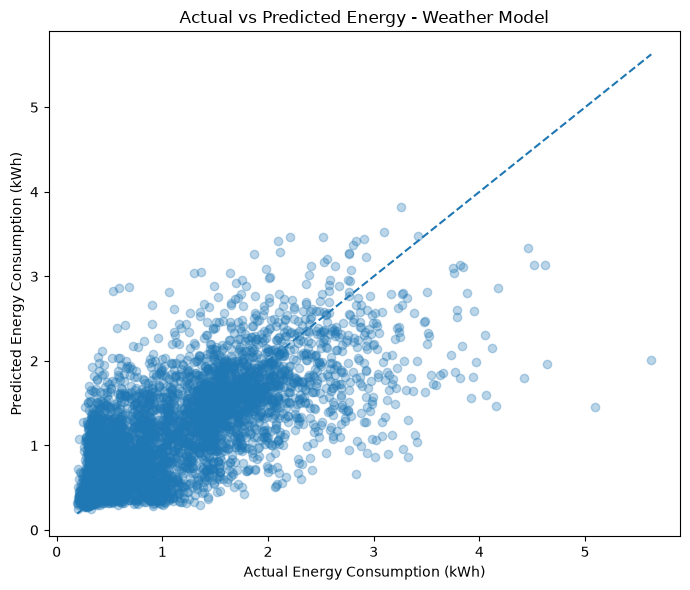

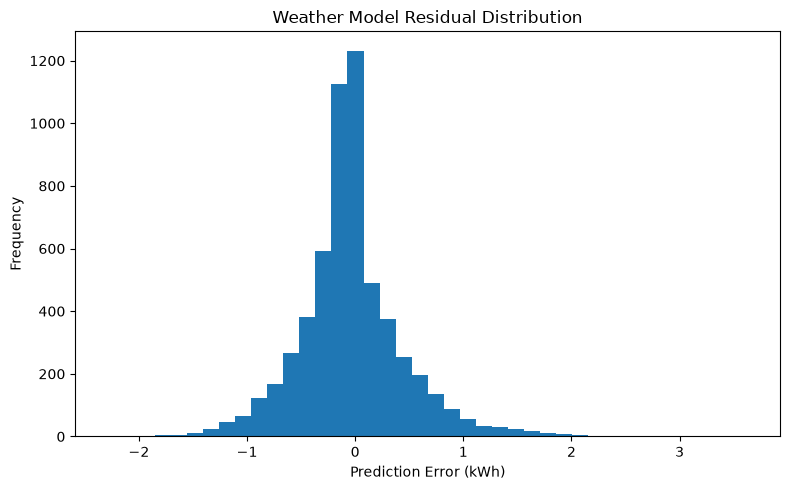

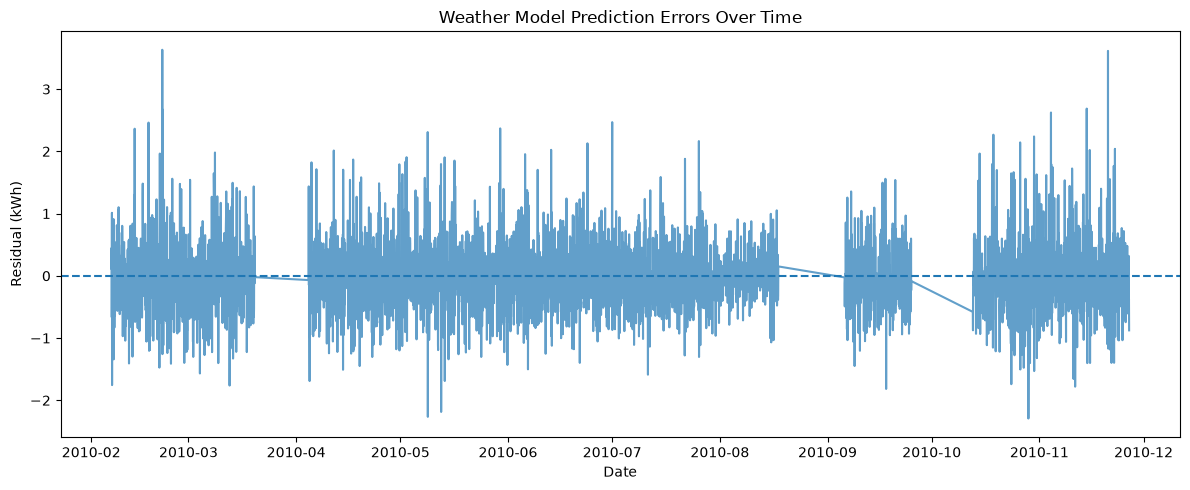


CELL 33 COMPLETED SUCCESSFULLY


In [122]:
# CELL 33: Weather Model Residual Analysis

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate residuals
residuals = y_test.values - weather_predictions

print("WEATHER MODEL RESIDUAL ANALYSIS")
print("=" * 50)

print("Mean Residual:", round(np.mean(residuals), 4))
print("Residual Standard Deviation:", round(np.std(residuals), 4))
print("Mean Absolute Error:", round(mean_absolute_error(y_test, weather_predictions), 4))
print("Root Mean Squared Error:", round(np.sqrt(mean_squared_error(y_test, weather_predictions)), 4))

# Actual vs Predicted scatter plot
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test.values,
    weather_predictions,
    alpha=0.3
)

min_value = min(y_test.min(), weather_predictions.min())
max_value = max(y_test.max(), weather_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Energy Consumption (kWh)")
plt.ylabel("Predicted Energy Consumption (kWh)")
plt.title("Actual vs Predicted Energy - Weather Model")
plt.tight_layout()
plt.show()

# Residual distribution
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=40)

plt.xlabel("Prediction Error (kWh)")
plt.ylabel("Frequency")
plt.title("Weather Model Residual Distribution")
plt.tight_layout()
plt.show()

# Residuals over time
plt.figure(figsize=(12, 5))

plt.plot(y_test.index, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")

plt.xlabel("Date")
plt.ylabel("Residual (kWh)")
plt.title("Weather Model Prediction Errors Over Time")
plt.tight_layout()
plt.show()

print("\nCELL 33 COMPLETED SUCCESSFULLY")

In [123]:
# CELL 34: Generate and Save Final Weather Forecasting Report

import os
import pandas as pd
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Create output directory
os.makedirs(EVALUATION_DIR, exist_ok=True)

# Calculate final metrics
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

weather_mae = mean_absolute_error(y_test, weather_predictions)
weather_rmse = np.sqrt(mean_squared_error(y_test, weather_predictions))
weather_r2 = r2_score(y_test, weather_predictions)

# Build final comparison report
final_weather_report = pd.DataFrame([
    {
        "Model": "Baseline (Without Weather)",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "R2": baseline_r2
    },
    {
        "Model": "Weather-Based Random Forest",
        "MAE": weather_mae,
        "RMSE": weather_rmse,
        "R2": weather_r2
    }
])

# Calculate improvement
rmse_improvement = (
    (baseline_rmse - weather_rmse) / baseline_rmse
) * 100

r2_improvement = weather_r2 - baseline_r2

# Save report
report_path = os.path.join(
    EVALUATION_DIR,
    "final_weather_forecasting_report.csv"
)

final_weather_report.to_csv(report_path, index=False)

# Save residual statistics
residual_report = pd.DataFrame([{
    "Mean_Residual": np.mean(residuals),
    "Residual_Std": np.std(residuals),
    "MAE": weather_mae,
    "RMSE": weather_rmse,
    "R2": weather_r2
}])

residual_path = os.path.join(
    EVALUATION_DIR,
    "weather_residual_analysis.csv"
)

residual_report.to_csv(residual_path, index=False)

print("FINAL WEATHER FORECASTING REPORT")
print("=" * 55)

display(final_weather_report.round(4))

print("\nRMSE improvement:", round(rmse_improvement, 4), "%")
print("R2 improvement:", round(r2_improvement, 4))

print("\nReport saved:", report_path)
print("Residual report saved:", residual_path)

print("\nTASK 3 WEATHER FORECASTING EVALUATION COMPLETED")


FINAL WEATHER FORECASTING REPORT


,Model,MAE,RMSE,R2
0,Baseline (Without Weather),0.3421,0.4956,0.5536
1,Weather-Based Random Forest,0.3418,0.4939,0.5566



RMSE improvement: 0.3367 %
R2 improvement: 0.003

Report saved: c:\Users\vyshu\OneDrive\Desktop\Smart-Energy-Forecasting\evaluation\weather_forecasting\final_weather_forecasting_report.csv
Residual report saved: c:\Users\vyshu\OneDrive\Desktop\Smart-Energy-Forecasting\evaluation\weather_forecasting\weather_residual_analysis.csv

TASK 3 WEATHER FORECASTING EVALUATION COMPLETED


In [124]:
# TEST: ENERGY SAVING RECOMMENDATION SYSTEM

import pandas as pd
import os
import sys

# Project directory
BASE_DIR = os.path.dirname(os.getcwd())

# Add src folder to Python path
SRC_DIR = os.path.join(BASE_DIR, "src")

if SRC_DIR not in sys.path:
    sys.path.append(SRC_DIR)

# Import recommendation functions
from recommendation_system import (
    analyze_energy_consumption,
    generate_recommendations,
    generate_high_consumption_report,
    print_recommendation_summary
)

# Load actual energy and weather data
DATA_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "energy_weather_merged.csv"
)

energy_df = pd.read_csv(
    DATA_PATH,
    parse_dates=["DateTime"],
    index_col="DateTime"
)

# Generate recommendations
recommendation_df = print_recommendation_summary(
    energy_df
)

# Generate high consumption report
high_consumption_report = generate_high_consumption_report(
    energy_df
)

# Display recommendations
print("\nRECOMMENDATION TABLE")
display(recommendation_df)

print("\nTOP 10 HIGH CONSUMPTION RECORDS")
display(high_consumption_report.head(10))


SMART ENERGY SAVING RECOMMENDATION SYSTEM

DATASET SUMMARY
--------------------------------------------------
Total hourly records: 31428
Average energy consumption: 1.0894 kWh
High consumption threshold: 2.3393 kWh
High consumption records: 3143

ENERGY SAVING RECOMMENDATIONS

1. High Consumption
Finding: 3143 hourly records are at or above 2.339 kWh.
Recommendation: Review the appliances and equipment operating during these high-consumption periods. Switch off unnecessary equipment and avoid running multiple high-power appliances simultaneously.
Priority: High
-----------------------------------------------------------------

2. Peak Usage Hours
Finding: Highest average hourly consumption occurs at 20:00, averaging 1.910 kWh.
Recommendation: Consider shifting flexible activities such as laundry, dishwashing and other non-essential equipment usage to lower-consumption hours, where practical.
Priority: High
-----------------------------------------------------------------

3. Daily Con

,Category,Finding,Recommendation,Priority
0,High Consumption,3143 hourly records are at or above 2.339 kWh.,Review the appliances and equipment operating ...,High
1,Peak Usage Hours,Highest average hourly consumption occurs at 2...,Consider shifting flexible activities such as ...,High
2,Daily Consumption,Highest daily consumption in the top 10% of da...,Review daily appliance usage and identify equi...,High
3,Load Scheduling,Lowest average hourly consumption occurs at 03...,Compare this lower-consumption period with pea...,Medium
4,Weekly Usage Pattern,Average weekend hourly consumption (1.228 kWh)...,Review weekend appliance usage and identify ac...,Medium
5,Weather-Based Insight,Temperature has a weak linear correlation with...,Temperature alone does not show a strong linea...,Medium
6,General Energy Saving,Continuous monitoring can help identify unnece...,"Turn off unused lights and appliances, use ene...",Medium



TOP 10 HIGH CONSUMPTION RECORDS


,Energy_kWh,Hour,Date
DateTime,,,
2008-11-23 18:00:00,6.560533,18,2008-11-23
2009-01-16 20:00:00,6.519633,20,2009-01-16
2008-02-02 19:00:00,6.496033,19,2008-02-02
2007-12-23 19:00:00,6.488000,19,2007-12-23
2007-02-22 21:00:00,6.363867,21,2007-02-22
2007-12-28 17:00:00,6.333667,17,2007-12-28
2008-11-23 20:00:00,6.310567,20,2008-11-23
2007-01-21 20:00:00,6.076567,20,2007-01-21
2008-01-26 19:00:00,6.013800,19,2008-01-26
